# GlobalStream — Retenção e segmentação de clientes
**Introduction to Machine Learning — Ciência de Dados (UniFECAF)**
**Aluno:** Antônio Benevaldo Chaves Santana

Estudo da planilha fornecida com 1.000 clientes. Comparamos perfis de uso (segmentação) e classificadores de churn para apoiar hipóteses de retenção. A base é estática: não há datas, histórico mensal nem horizonte documentado do Churn. Portanto, os escores classificam o **churn registrado**, sem demonstrar previsão de cancelamento no próximo mês ou efeito de campanhas.

**Como executar**
1. Instale as dependências: `pip install -r requirements.txt` (Python 3.10 ou mais novo).
2. Mantenha `globalstream_data.xlsx` na mesma pasta do notebook (no Google Colab, a célula de carregamento pede o upload do arquivo).
3. Execute todas as células em ordem (*Kernel → Restart & Run All*). A validação cruzada aninhada faz centenas de ajustes e leva alguns minutos.

Gráficos, tabelas e o arquivo `resultados.json` são gravados na pasta `resultados/`. A última célula de código mostra um resumo dos números-chave.

**Roteiro:** 1. Exploração e limpeza · 2. Segmentação (K-Means + PCA) · 3. Classificação · 4. Avaliação · 5. Análise crítica.

In [1]:
# Bibliotecas
import json
import sys, platform, hashlib, importlib.metadata
from IPython.display import display, Markdown
if sys.version_info < (3, 10):
    raise RuntimeError('Este notebook requer Python 3.10 ou mais novo.')
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency, kruskal

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, adjusted_rand_score, average_precision_score,
                             classification_report, confusion_matrix, davies_bouldin_score,
                             f1_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve, silhouette_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split, validation_curve)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
import sklearn

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
pd.set_option('display.max_colwidth', 120)

# Configuração geral
SEED = 42                                   # reprodutibilidade
PASTA = Path('resultados'); PASTA.mkdir(exist_ok=True)
RES = {}                                    # números-chave reaproveitados no relatório

# Paleta (azul = permanece, laranja = cancela) e estilo dos gráficos
AZUL, LARANJA, AQUA, AMARELO = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
MAGENTA, VERDE, VIOLETA, VERMELHO = '#e87ba4', '#008300', '#4a3aa7', '#e34948'
SERIES = [AZUL, LARANJA, AQUA, AMARELO, MAGENTA, VERDE, VIOLETA, VERMELHO]
TINTA, TINTA2, MUDO, CINZA, GRADE = '#0b0b0b', '#52514e', '#898781', '#c3c2b7', '#e1e0d9'
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'axes.edgecolor': CINZA, 'axes.labelcolor': TINTA2, 'xtick.color': TINTA2, 'ytick.color': TINTA2,
    'axes.titlecolor': TINTA, 'axes.titlesize': 10.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRADE,
    'grid.linewidth': 0.6, 'axes.axisbelow': True, 'font.size': 9, 'legend.frameon': False,
    'lines.linewidth': 2, 'figure.dpi': 100})

def salvar(fig, nome):
    """Salva a figura em resultados/ e exibe no notebook."""
    fig.tight_layout()
    fig.savefig(PASTA / nome, dpi=160, bbox_inches='tight')
    plt.show()

def pct(x, casas=1):
    return f'{100 * x:.{casas}f}%'.replace('.', ',')

def brl(x):
    return 'u.m. ' + f'{x:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

def num(x, casas=2):
    return f'{x:.{casas}f}'.replace('.', ',')

print('Python:', platform.python_version(), '| Sistema:', platform.system())
print('Versões → pandas', pd.__version__, '| scikit-learn', sklearn.__version__, '| numpy', np.__version__)


Python: 3.12.14 | Sistema: Linux
Versões → pandas 2.2.3 | scikit-learn 1.8.0 | numpy 2.3.5


In [2]:
# Carregamento da base oficial do enunciado
# Opcional: informe o caminho completo, mantendo o r antes das aspas.
# Exemplo: ARQUIVO_EXCEL = r"C:\Users\SeuNome\Downloads\globalstream_data.xlsx"
ARQUIVO_EXCEL = ""
NOME_PLANILHA = "globalstream_data.xlsx"


def localizar_planilha(caminho_manual=""):
    """Procura a planilha na pasta do notebook; no Colab pede upload; no Windows abre um seletor."""
    if caminho_manual.strip():
        arquivo = Path(caminho_manual).expanduser()
        if not arquivo.is_file():
            raise FileNotFoundError(f"Confira o caminho informado em ARQUIVO_EXCEL: {arquivo}")
        return arquivo.resolve()

    # O diretório do kernel pode ser diferente da pasta do notebook.
    for pasta in (Path.cwd(), Path.cwd().parent):
        for subpasta in (Path("."), Path("dados")):
            arquivo = pasta / subpasta / NOME_PLANILHA
            if arquivo.is_file():
                return arquivo.resolve()

    if "google.colab" in sys.modules:                      # Google Colab: upload pelo navegador
        from google.colab import files
        enviados = files.upload()
        if enviados:
            nome = next(iter(enviados))
            Path(NOME_PLANILHA).write_bytes(enviados[nome])
            return Path(NOME_PLANILHA).resolve()

    if sys.platform == "win32":                            # Windows: janela para escolher o arquivo
        try:
            import tkinter as tk
            from tkinter import filedialog
            janela = tk.Tk()
            try:
                janela.withdraw()
                janela.attributes("-topmost", True)
                escolhido = filedialog.askopenfilename(
                    parent=janela, title=f"Selecione a planilha {NOME_PLANILHA}",
                    filetypes=[("Planilha Excel", "*.xlsx")])
            finally:
                janela.destroy()
            if escolhido and Path(escolhido).is_file():
                return Path(escolhido).resolve()
        except Exception as erro:
            print(f"Seletor indisponível ({erro}).")

    raise FileNotFoundError(
        f"Planilha não localizada a partir de {Path.cwd()}. Mantenha {NOME_PLANILHA} "
        "junto do notebook ou informe o caminho completo em ARQUIVO_EXCEL nesta célula.")


CAMINHO_DADOS = localizar_planilha(ARQUIVO_EXCEL)
df_bruto = pd.read_excel(CAMINHO_DADOS, engine="openpyxl")
print(f"Planilha carregada: {CAMINHO_DADOS.name}")
print(f'Formato: {df_bruto.shape[0]} linhas × {df_bruto.shape[1]} colunas')
display(df_bruto.head())
df_bruto.info()

Planilha carregada: globalstream_data.xlsx
Formato: 1000 linhas × 9 colunas
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID_Cliente                 1000 non-null   object 
 1   Meses_Contrato             1000 non-null   int64  
 2   Valor_Mensal               1000 non-null   float64
 3   Frequencia_Acesso_Semanal  1000 non-null   int64  
 4   Tickets_Suporte            1000 non-null   int64  
 5   Plano                      1000 non-null   object 
 6   Genero_Favorito            1000 non-null   object 
 7   Dispositivo_Principal      1000 non-null   object 
 8   Churn                      1000 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 70.4+ KB


,ID_Cliente,Meses_Contrato,Valor_Mensal,Frequencia_Acesso_Semanal,Tickets_Suporte,Plano,Genero_Favorito,Dispositivo_Principal,Churn
0,GS-0001,39,39.57,5,6,Standard,Desporto,Smart TV,1
1,GS-0002,29,54.20,7,5,Premium,Documentarios,Web,0
2,GS-0003,15,37.54,4,8,Basico,Documentarios,Mobile,1
3,GS-0004,43,50.35,2,2,Basico,Filmes,Mobile,0
4,GS-0005,8,52.71,5,2,Premium,Series,Smart TV,0


**Dicionário e convenções de interpretação**

| Coluna | Papel | Interpretação adotada e limite |
|---|---|---|
| ID_Cliente | Chave | Identificador excluído dos modelos; deve ser único e preenchido. |
| Meses_Contrato | Numérica | Meses informados no contrato; não está documentado se é duração contratada ou tempo de relacionamento. |
| Valor_Mensal | Numérica | Valor mensal; a moeda não está documentada. Custos apresentados em unidades monetárias hipotéticas (u.m.). |
| Frequencia_Acesso_Semanal | Numérica | Frequência informada de 0 a 7; não se presume que sejam dias nem horas assistidas. |
| Tickets_Suporte | Numérica | Contagem de chamados; motivo e janela de acumulação desconhecidos. |
| Plano, Genero_Favorito, Dispositivo_Principal | Categóricas | Categorias nominais, usadas no classificador e na descrição dos grupos. |
| Churn | Alvo | Convenção: 1 representa cancelamento e 0 permanência; horizonte desconhecido. |

As regras de domínio são convenções de validação para este exercício, não um dicionário oficial da empresa.


## 1. Exploração e limpeza dos dados
### 1.1 Auditoria e separação antecipada
A auditoria estrutural confere colunas, duplicatas, IDs, tipos, domínios e alvo. Cópias exatas são removidas; IDs conflitantes impedem a análise. Categorias são padronizadas por espaços e caixa, e valores numéricos inválidos ou não finitos viram ausentes. Em seguida, reservamos 20% para teste. Toda exploração orientada ao modelo usa os 80% de treino.


In [3]:
NUM = ['Meses_Contrato', 'Valor_Mensal', 'Frequencia_Acesso_Semanal', 'Tickets_Suporte']
CAT = ['Plano', 'Genero_Favorito', 'Dispositivo_Principal']
ALVO = 'Churn'
# Domínio válido (mínimo, máximo) de cada variável numérica; None = sem limite
DOMINIO = {'Meses_Contrato': (1, None), 'Valor_Mensal': (0.01, None),
           'Frequencia_Acesso_Semanal': (0, 7), 'Tickets_Suporte': (0, None)}

df = df_bruto.copy()
esperadas = ['ID_Cliente', *NUM, *CAT, ALVO]
if set(esperadas) - set(df.columns):
    raise ValueError(f'Colunas ausentes: {sorted(set(esperadas) - set(df.columns))}')

# (a) duplicatas
dup_linhas = int(df.duplicated().sum())
dup_ids = int(df['ID_Cliente'].duplicated().sum())
dup_sem_id = int(df.drop(columns='ID_Cliente').duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
if df['ID_Cliente'].isna().any() or df['ID_Cliente'].astype(str).str.strip().eq('').any():
    raise ValueError('IDs vazios')
if df['ID_Cliente'].duplicated().any():
    raise ValueError('IDs repetidos com registros conflitantes')

# (b) padronização de texto nas categóricas: espaços extras e variações de maiúsculas
variantes = {}
for c in CAT:
    df[c] = df[c].map(lambda v: str(v).strip() if pd.notna(v) and str(v).strip() else np.nan)
    chave = df[c].str.casefold()
    # grafia padrão = forma original mais frequente de cada categoria (preserva, p. ex., "Smart TV")
    grafia = df.groupby(chave)[c].agg(lambda s: s.value_counts().index[0])
    variantes[c] = int(df[c].nunique() - chave.nunique())
    df[c] = chave.map(grafia)

# (c) domínio das numéricas: valores impossíveis viram ausentes
invalidos = {}
for c, (mn, mx) in DOMINIO.items():
    v = pd.to_numeric(df[c], errors='coerce')
    mask = (v.isna() & df[c].notna()) | (v.notna() & ~np.isfinite(v))   # texto inválido ou infinito
    if c != 'Valor_Mensal': mask |= (v % 1 != 0) & v.notna()
    if mn is not None: mask |= v < mn
    if mx is not None: mask |= v > mx
    invalidos[c] = int(mask.sum())
    df[c] = v.mask(mask)

# (d) alvo: somente 0/1 e sem ausentes
assert df[ALVO].isin([0, 1]).all(), 'Alvo com valores fora de {0, 1}'

auditoria = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'ausentes': df.isna().sum(),
    'valores únicos': df.nunique(),
    'fora do domínio': pd.Series(invalidos),
    'variantes de texto': pd.Series(variantes),
})
for col in ['fora do domínio', 'variantes de texto']:
    auditoria[col] = auditoria[col].map(lambda v: '—' if pd.isna(v) else int(v))
display(auditoria)
print(f'Linhas duplicadas: {dup_linhas} | IDs repetidos: {dup_ids} | '
      f'clientes idênticos ignorando o ID: {dup_sem_id}')
for c in CAT:
    print(f'{c}: {sorted(df[c].dropna().unique())}')

RES['auditoria'] = dict(linhas=len(df), colunas=df_bruto.shape[1], ausentes=int(df.isna().sum().sum()),
                        duplicatas=dup_linhas, ids_repetidos=dup_ids, fora_dominio=int(sum(invalidos.values())),
                        variantes_texto=int(sum(variantes.values())))

# Split antes de qualquer exploração orientada a atributos ou ao alvo.
X = df[NUM + CAT].copy(); y = df[ALVO].astype(int)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
df_eda = df.loc[X_tr.index].copy()
assert set(X_tr.index).isdisjoint(X_te.index)
RES['fonte'] = {'arquivo': CAMINHO_DADOS.name, 'sha256': hashlib.sha256(CAMINHO_DADOS.read_bytes()).hexdigest(), 'linhas':len(df), 'colunas':len(df_bruto.columns)}
RES['taxa_churn_base'] = float(y.mean())
pd.DataFrame({'ID_Cliente':df.ID_Cliente, 'particao':np.where(df.index.isin(X_tr.index),'treino','teste')}).to_csv(PASTA/'particoes.csv',index=False)
print(f'Reservados {len(X_tr)} clientes de treino e {len(X_te)} de teste.')


Linhas duplicadas: 0 | IDs repetidos: 0 | clientes idênticos ignorando o ID: 0
Plano: ['Basico', 'Premium', 'Standard']
Genero_Favorito: ['Desporto', 'Documentarios', 'Filmes', 'Series']
Dispositivo_Principal: ['Mobile', 'Smart TV', 'Web']
Reservados 800 clientes de treino e 200 de teste.


,tipo,ausentes,valores únicos,fora do domínio,variantes de texto
Churn,int64,0,2,—,—
Dispositivo_Principal,object,0,3,—,0
Frequencia_Acesso_Semanal,int64,0,8,0,—
Genero_Favorito,object,0,4,—,0
ID_Cliente,object,0,1000,—,—
Meses_Contrato,int64,0,47,0,—
Plano,object,0,3,—,0
Tickets_Suporte,int64,0,10,0,—
Valor_Mensal,float64,0,839,0,—


### 1.2 Tratamento de ausentes
Mediana para numéricas e moda para categóricas são aprendidas no treino de cada pipeline. A segmentação também usa `SimpleImputer` antes de escala e K-Means. Na exploração, gráficos ignoram valores ausentes e conversões usam inteiros anuláveis. Não se inserem falhas nos dados originais: os testes de robustez usam cópias separadas.


In [4]:
ausentes_total = int(df.isna().sum().sum())
print(f'Total de células ausentes após a auditoria: {ausentes_total}')
print('Estratégia: SimpleImputer(median) nas numéricas e SimpleImputer(most_frequent) nas categóricas, dentro do Pipeline.')

Total de células ausentes após a auditoria: 0
Estratégia: SimpleImputer(median) nas numéricas e SimpleImputer(most_frequent) nas categóricas, dentro do Pipeline.


### 1.3 Verificações semânticas no treino
Meses acima de 36 exigem esclarecimento **se** o campo representar tempo de relacionamento e não houver migração de clientes. Se indicar duração contratada, não são necessariamente um erro. Diferenças de preço entre planos também dependem de informações sobre descontos e regras comerciais que não foram fornecidas.


Clientes com Meses_Contrato > 36: 187 (23,4%) no treino — máximo observado: 47 meses
Kruskal-Wallis (Valor_Mensal entre planos): H = 4.55, p = 0.103


,count,mean,50%,min,max
Plano,,,,,
Basico,261.0,45.11,46.02,30.29,59.84
Premium,270.0,45.89,46.77,30.07,59.88
Standard,269.0,44.34,44.57,30.05,59.67


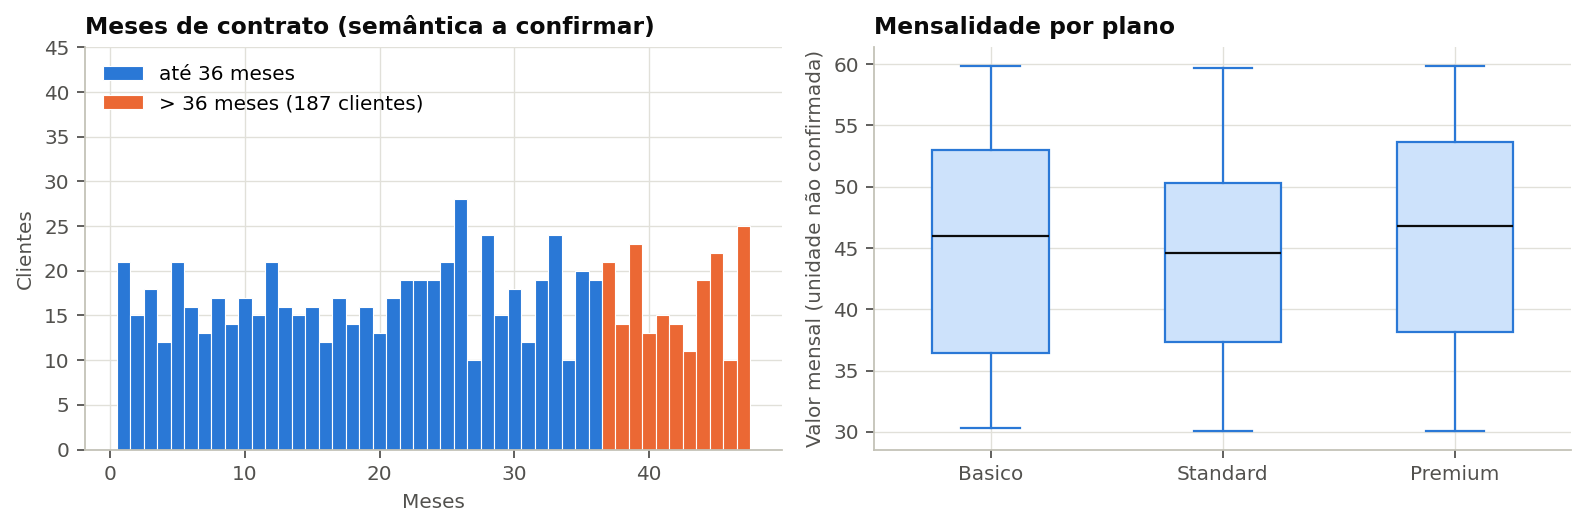

In [5]:
acima_36 = int((df_eda['Meses_Contrato'] > 36).sum())
print(f'Clientes com Meses_Contrato > 36: {acima_36} ({pct(acima_36 / len(df_eda))}) no treino — máximo observado: {int(df_eda.Meses_Contrato.max())} meses')

resumo_plano = df_eda.groupby('Plano')['Valor_Mensal'].describe()[['count', 'mean', '50%', 'min', 'max']].round(2)
display(resumo_plano)
h_kw, p_kw = kruskal(*[g['Valor_Mensal'] for _, g in df_eda.groupby('Plano')])
print(f'Kruskal-Wallis (Valor_Mensal entre planos): H = {h_kw:.2f}, p = {p_kw:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(df_eda.loc[df_eda.Meses_Contrato <= 36, 'Meses_Contrato'], bins=np.arange(0.5, 48.5), color=AZUL, edgecolor='white', linewidth=0.5, label='até 36 meses')
ax[0].hist(df_eda.loc[df_eda.Meses_Contrato > 36, 'Meses_Contrato'], bins=np.arange(0.5, 48.5), color=LARANJA, edgecolor='white', linewidth=0.5, label=f'> 36 meses ({acima_36} clientes)')
ax[0].legend(loc='upper left', bbox_to_anchor=(0, 1.0)); ax[0].set_ylim(0, 45)
ax[0].set(title='Meses de contrato (semântica a confirmar)', xlabel='Meses', ylabel='Clientes')
ordem = ['Basico', 'Standard', 'Premium']
bp = ax[1].boxplot([df_eda.loc[df_eda.Plano == p, 'Valor_Mensal'] for p in ordem], widths=0.5, patch_artist=True,
                   medianprops=dict(color=TINTA), boxprops=dict(facecolor='#cde2fb', edgecolor=AZUL),
                   whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL))
ax[1].set_xticks([1, 2, 3]); ax[1].set_xticklabels(ordem)
ax[1].set(title='Mensalidade por plano', ylabel='Valor mensal (unidade não confirmada)')
salvar(fig, 'fig05_inconsistencias.png')

RES['inconsistencias'] = dict(acima_36=acima_36, pct_acima_36=acima_36 / len(df_eda), max_meses=int(df_eda.Meses_Contrato.max()),
                              medias_plano=resumo_plano['mean'].to_dict(), p_kruskal=float(p_kw))


**Decisão:** preservar os registros. Não há suporte para truncar automaticamente contratos nem classificar a base como sintética. O Kruskal-Wallis investiga diferenças nas distribuições dos valores entre planos; ausência de significância não comprova igualdade ou independência. A análise de sensibilidade com limite de 36 meses é apenas exploratória.


### 1.4 Análise de outliers
IQR (1,5 vezes o intervalo interquartil) e escore z (módulo maior que 3) são calculados somente no treino. Dados ausentes são ignorados nos resumos e gráficos. Um valor extremo estatístico não é automaticamente erro.


,mín,máx,limite inf. IQR,limite sup. IQR,outliers IQR,|z| > 3
variável,,,,,,
Meses_Contrato,1.00,47.00,-22.12,70.88,0,0
Valor_Mensal,30.05,59.88,14.17,75.87,0,0
Frequencia_Acesso_Semanal,0.00,7.00,-6.50,13.50,0,0
Tickets_Suporte,0.00,9.00,-5.50,14.50,0,0


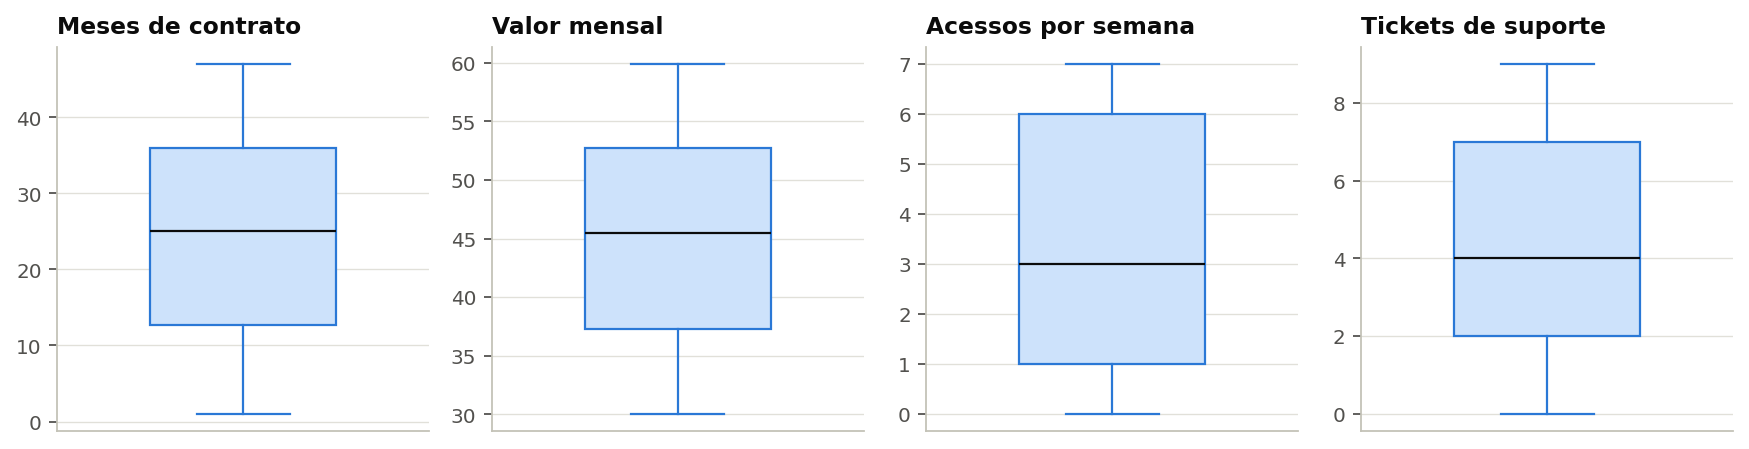

In [6]:
linhas = []
for c in NUM:
    q1, q3 = df_eda[c].quantile([0.25, 0.75]); iqr = q3 - q1
    li, ls = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (df_eda[c] - df_eda[c].mean()) / df_eda[c].std()
    linhas.append({'variável': c, 'mín': df_eda[c].min(), 'máx': df_eda[c].max(), 'limite inf. IQR': round(li, 2),
                   'limite sup. IQR': round(ls, 2), 'outliers IQR': int(((df_eda[c] < li) | (df_eda[c] > ls)).sum()),
                   '|z| > 3': int((z.abs() > 3).sum())})
tab_out = pd.DataFrame(linhas).set_index('variável')
display(tab_out)

fig, axs = plt.subplots(1, 4, figsize=(11, 2.9))
rotulos = ['Meses de contrato', 'Valor mensal', 'Acessos por semana', 'Tickets de suporte']
for a, c, r in zip(axs, NUM, rotulos):
    a.boxplot(df_eda[c].dropna(), widths=0.5, patch_artist=True, medianprops=dict(color=TINTA),
              boxprops=dict(facecolor='#cde2fb', edgecolor=AZUL), whiskerprops=dict(color=AZUL),
              capprops=dict(color=AZUL), flierprops=dict(markeredgecolor=LARANJA))
    a.set_title(r); a.set_xticks([])
salvar(fig, 'fig06_outliers.png')
RES['outliers'] = dict(iqr=int(tab_out['outliers IQR'].sum()), z=int(tab_out['|z| > 3'].sum()))


**Decisão de tratamento:** consulte a tabela calculada acima. Na base fornecida, a auditoria não identifica extremos por IQR ou z; os valores são preservados. Valores que violam as regras de domínio viram ausentes e recebem imputação nos pipelines. Se surgirem extremos plausíveis em outra base, é necessário avaliar seu significado e testar eventual limitação aprendida somente no treino. Não há winsorização silenciosa nesta versão.


### 1.5 Encoding categórico
Plano, gênero e dispositivo usam one-hot. Isso evita impor distâncias artificiais entre categorias. `handle_unknown='ignore'` permite prever categorias novas; a imputação de categorias ocorre antes. A demonstração abaixo ajusta somente o treino; o classificador reaprende seus transformadores dentro de cada dobra.


In [7]:
imputador_demo = SimpleImputer(strategy='most_frequent').fit(df_eda[CAT])
cat_demo = pd.DataFrame(imputador_demo.transform(df_eda[CAT]),columns=CAT,index=df_eda.index)
enc_demo = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(cat_demo)
colunas_ohe = list(enc_demo.get_feature_names_out(CAT))
print(f'{len(CAT)} categóricas → {len(colunas_ohe)} colunas; ajuste somente no treino')
display(pd.DataFrame(enc_demo.transform(cat_demo.head(3)),columns=colunas_ohe).astype(int))


3 categóricas → 10 colunas; ajuste somente no treino


,Plano_Basico,Plano_Premium,Plano_Standard,Genero_Favorito_Desporto,Genero_Favorito_Documentarios,Genero_Favorito_Filmes,Genero_Favorito_Series,Dispositivo_Principal_Mobile,Dispositivo_Principal_Smart TV,Dispositivo_Principal_Web
0,1,0,0,0,1,0,0,0,1,0
1,0,1,0,1,0,0,0,0,1,0
2,0,1,0,1,0,0,0,0,0,1


### 1.6 Exploração do conjunto de treino
As distribuições, taxas por categoria e correlações abaixo se referem apenas aos clientes de treino. São associações observadas, não relações causais nem estimativas de mudança ao longo do tempo.


Clientes que cancelaram: 434 de 800 → taxa de churn de 54,2%


,count,mean,std,min,25%,50%,75%,max
Meses_Contrato,800.0,24.31,13.53,1.00,12.75,25.00,36.00,47.00
Valor_Mensal,800.0,45.11,8.68,30.05,37.30,45.47,52.73,59.88
Frequencia_Acesso_Semanal,800.0,3.47,2.29,0.00,1.00,3.00,6.00,7.00
Tickets_Suporte,800.0,4.37,2.84,0.00,2.00,4.00,7.00,9.00


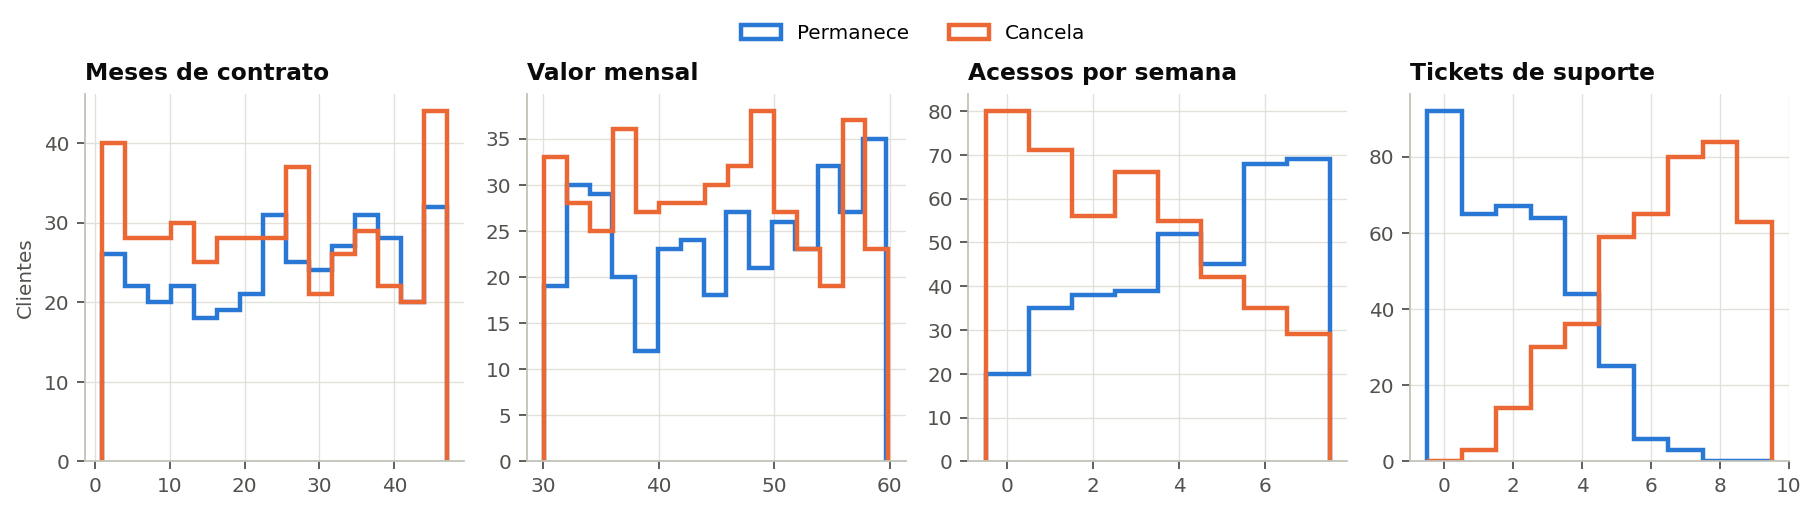

In [8]:
taxa_churn = df_eda[ALVO].mean()
print(f'Clientes que cancelaram: {int(df_eda[ALVO].sum())} de {len(df_eda)} → taxa de churn de {pct(taxa_churn)}')
display(df_eda[NUM].describe().T.round(2))

fig, axs = plt.subplots(1, 4, figsize=(11.5, 3))
for a, c, r in zip(axs, NUM, rotulos):
    lim = (df_eda[c].min(), df_eda[c].max())
    bins = np.arange(lim[0] - 0.5, lim[1] + 1.5) if c in ['Frequencia_Acesso_Semanal', 'Tickets_Suporte'] else 15
    for valor, cor, nome in [(0, AZUL, 'Permanece'), (1, LARANJA, 'Cancela')]:
        a.hist(df_eda.loc[df_eda[ALVO] == valor, c].dropna(), bins=bins, histtype='step', lw=2, color=cor, label=nome)
    a.set_title(r); a.set_ylabel('Clientes' if c == NUM[0] else '')
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.07))
salvar(fig, 'fig01_distribuicoes.png')
RES['taxa_churn'] = float(taxa_churn); RES['n_clientes'] = int(len(df_eda)); RES['n_churn'] = int(df_eda[ALVO].sum())


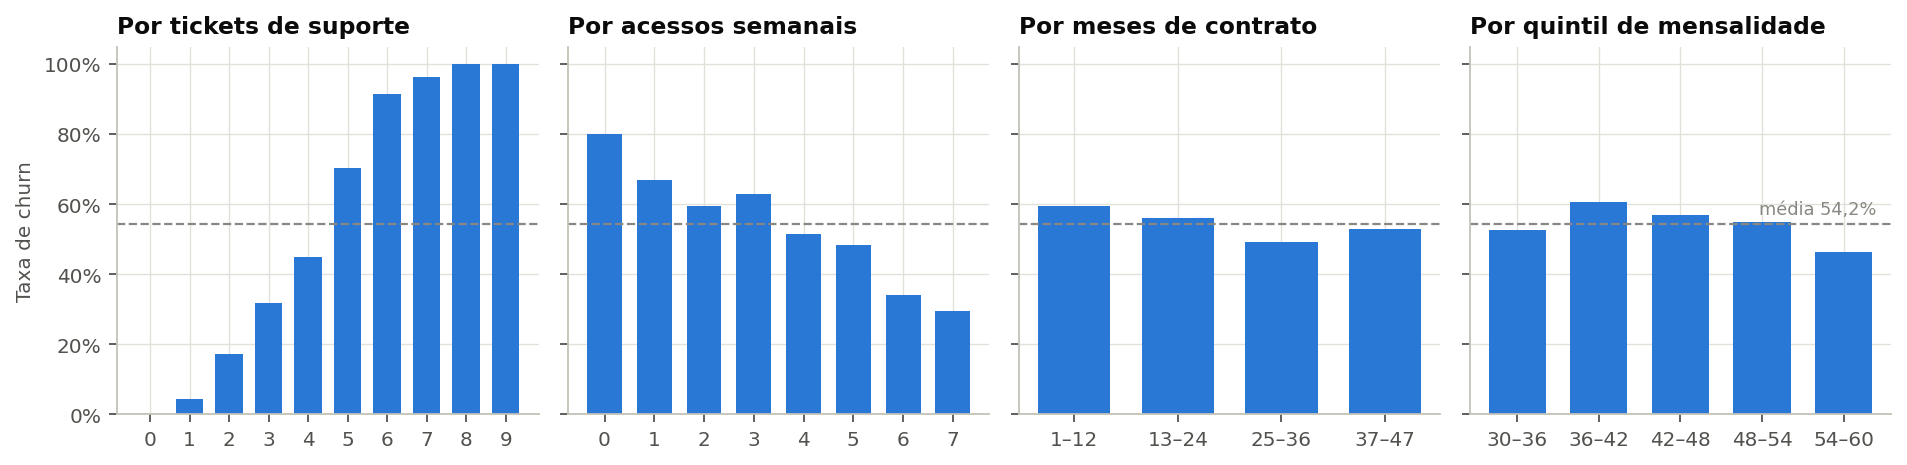

In [9]:
# Taxa de churn por nível de cada variável numérica (faixas para as contínuas)
faixas = {
    'Tickets_Suporte': df_eda['Tickets_Suporte'].astype('Int64'),
    'Frequencia_Acesso_Semanal': df_eda['Frequencia_Acesso_Semanal'].astype('Int64'),
    'Meses_Contrato': pd.cut(df_eda['Meses_Contrato'], [0, 12, 24, 36, 48], labels=['1–12', '13–24', '25–36', '37–47']),
    'Valor_Mensal': pd.qcut(df_eda['Valor_Mensal'], 5, duplicates='drop'),
}
# Rótulos curtos para os quintis da mensalidade (ex.: "30–36")
faixas['Valor_Mensal'] = faixas['Valor_Mensal'].cat.rename_categories(
    [f'{i.left:.0f}–{i.right:.0f}' for i in faixas['Valor_Mensal'].cat.categories])
titulos = {'Tickets_Suporte': 'Por tickets de suporte', 'Frequencia_Acesso_Semanal': 'Por acessos semanais',
           'Meses_Contrato': 'Por meses de contrato', 'Valor_Mensal': 'Por quintil de mensalidade'}
fig, axs = plt.subplots(1, 4, figsize=(12, 3), sharey=True)
taxas_num = {}
for a, (c, f) in zip(axs, faixas.items()):
    t = df_eda.groupby(f, observed=True)[ALVO].mean()
    taxas_num[c] = t.round(3).to_dict()
    a.bar(t.index.astype(str), t.values, color=AZUL, width=0.7)
    a.axhline(taxa_churn, color=MUDO, ls='--', lw=1)
    a.set_title(titulos[c]); a.set_ylim(0, 1.05)
axs[0].set_ylabel('Taxa de churn')
axs[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
axs[3].text(4.4, taxa_churn + 0.03, f'média {pct(taxa_churn)}', ha='right', color=MUDO, fontsize=8)
salvar(fig, 'fig02_taxa_churn_numericas.png')
RES['taxas_num'] = {k: {str(i): v for i, v in d.items()} for k, d in taxas_num.items()}


,menor taxa,maior taxa,qui²,p-valor
variável,,,,
Plano,"Basico (51,7%)","Standard (58,7%)",3.30,0.1921
Genero_Favorito,"Series (48,1%)","Documentarios (61,8%)",9.04,0.0287
Dispositivo_Principal,"Smart TV (50,6%)","Web (58,0%)",2.99,0.2245


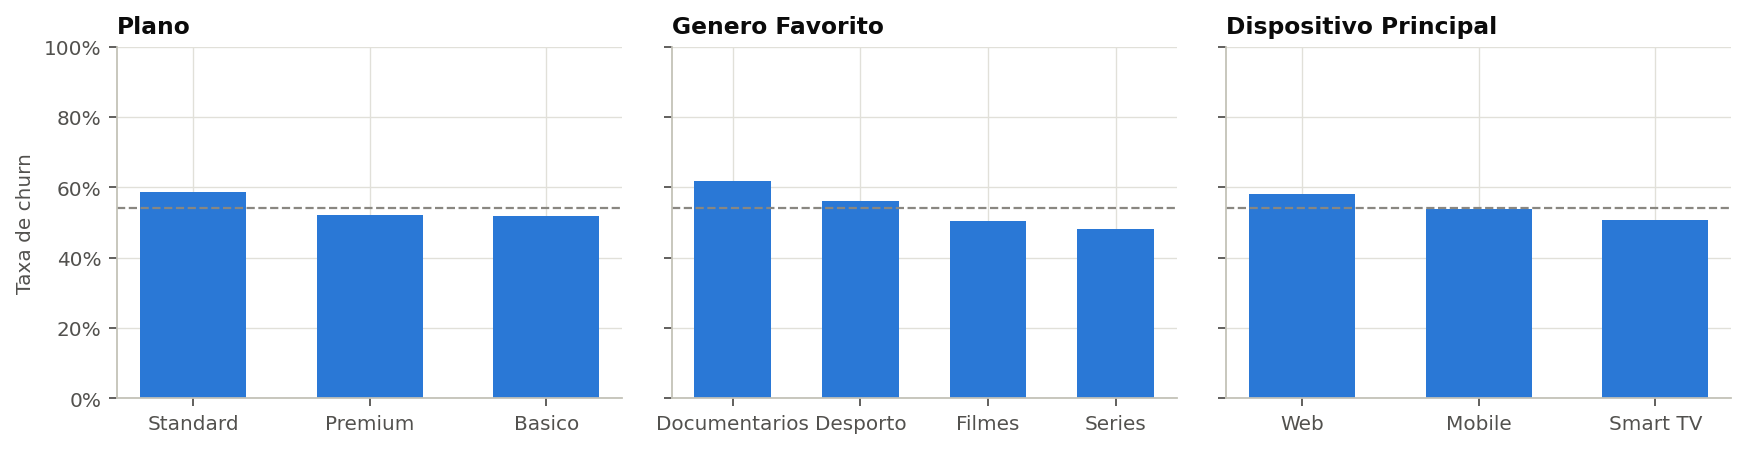

In [10]:
# Taxa de churn por categoria + teste qui-quadrado de independência
fig, axs = plt.subplots(1, 3, figsize=(11, 2.9), sharey=True)
testes = []
for a, c in zip(axs, CAT):
    t = df_eda.groupby(c)[ALVO].mean().sort_values(ascending=False)
    a.bar(t.index, t.values, color=AZUL, width=0.6)
    a.axhline(taxa_churn, color=MUDO, ls='--', lw=1)
    a.set_title(c.replace('_', ' ')); a.set_ylim(0, 1)
    chi2, p, _, _ = chi2_contingency(pd.crosstab(df_eda[c], df_eda[ALVO]))
    testes.append({'variável': c, 'menor taxa': f'{t.idxmin()} ({pct(t.min())})',
                   'maior taxa': f'{t.idxmax()} ({pct(t.max())})', 'qui²': round(chi2, 2), 'p-valor': round(p, 4)})
axs[0].set_ylabel('Taxa de churn')
axs[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
salvar(fig, 'fig03_taxa_churn_categoricas.png')
tab_chi = pd.DataFrame(testes).set_index('variável')
display(tab_chi)
RES['chi2'] = tab_chi['p-valor'].to_dict()


,correlação com churn
Frequencia_Acesso_Semanal,-0.309
Meses_Contrato,-0.060
Valor_Mensal,-0.059
Tickets_Suporte,0.754


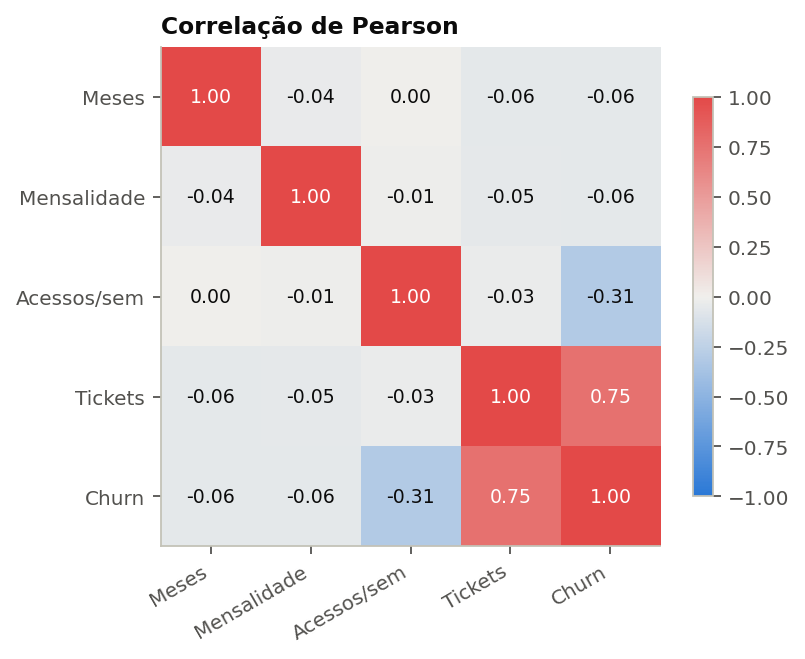

In [11]:
# Correlação (Pearson) entre numéricas e o alvo
corr = df_eda[NUM + [ALVO]].corr()
cmap_div = LinearSegmentedColormap.from_list('div', [AZUL, '#f0efec', VERMELHO])
nomes_curtos = ['Meses', 'Mensalidade', 'Acessos/sem', 'Tickets', 'Churn']
fig, ax = plt.subplots(figsize=(5.2, 4.2))
im = ax.imshow(corr, cmap=cmap_div, vmin=-1, vmax=1)
ax.set_xticks(range(5)); ax.set_xticklabels(nomes_curtos, rotation=30, ha='right')
ax.set_yticks(range(5)); ax.set_yticklabels(nomes_curtos); ax.grid(False)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8.5,
                color='white' if abs(corr.iloc[i, j]) > 0.6 else TINTA)
ax.set_title('Correlação de Pearson')
fig.colorbar(im, ax=ax, shrink=0.8)
salvar(fig, 'fig04_correlacao.png')
RES['corr_alvo'] = corr[ALVO].drop(ALVO).round(3).to_dict()
display(corr[ALVO].drop(ALVO).sort_values().round(3).to_frame('correlação com churn'))


**Leitura da exploração (treino, 800 clientes, churn de 54,2%)**
- **Tickets de suporte** é o sinal mais forte: nenhum cliente sem tickets cancelou; a taxa passa de 70% com 5 tickets e chega a 100% com 8 ou mais (correlação de 0,75 com o churn).
- **Frequência de acesso** atua no sentido oposto: 80% de churn com frequência 0 e 30% com frequência 7 (correlação de −0,31).
- **Meses de contrato e mensalidade** variam pouco em torno da média (correlações de −0,06).
- **Categorias:** plano (p = 0,19) e dispositivo (p = 0,22) não mostram associação significativa. O gênero favorito tem associação fraca, significativa a 5% (p = 0,029; Documentários 61,8% × Séries 48,1%), mas não resiste à correção de Bonferroni para três testes (0,05/3 ≈ 0,017) e quase não contribui para o classificador (seção 4).

São associações observadas, não relações causais: um chamado não necessariamente causa o cancelamento, e aumentar acessos não necessariamente produz retenção. Testes sem significância indicam evidência insuficiente para rejeitar a hipótese nula, não ausência comprovada de efeito. Mantemos as sete variáveis no classificador e discutimos a temporalidade dos tickets antes de qualquer uso operacional.

## 2. Segmentação de clientes
### 2.1 Variáveis e algoritmo
K-Means agrupa frequência, tickets e meses informados, após imputação e padronização. O alvo e o ID ficam excluídos. Preço e categorias são comparados como alternativas de representação, mas as categorias permanecem disponíveis para descrição dos perfis.

A silhouette depende do espaço e da distância: comparar valores entre representações diferentes é diagnóstico exploratório, não prova de que uma variável seja inútil. Para manter uma representação interpretável, a análise principal usa as três variáveis indicadas, com decisão explícita. Todos os ajustes usam **somente o treino**; novos clientes recebem o grupo com `predict`.


In [12]:
SEG = ['Frequencia_Acesso_Semanal', 'Tickets_Suporte', 'Meses_Contrato']
def preparo_segmentacao():
    return Pipeline([('imputacao',SimpleImputer(strategy='median',keep_empty_features=True)),('escala',StandardScaler())])
def matriz(num_cols,cat_cols=()):
    partes=[preparo_segmentacao().fit_transform(df_eda[num_cols])]
    if len(cat_cols):
        partes.append(Pipeline([('imputacao',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(sparse_output=False,handle_unknown='ignore'))]).fit_transform(df_eda[list(cat_cols)]))
    return np.hstack(partes)
alternativas={'Comportamento (3 variáveis)':matriz(SEG),'Comportamento + mensalidade':matriz(SEG+['Valor_Mensal']),'Comportamento + mensalidade + categóricas':matriz(SEG+['Valor_Mensal'],CAT)}
comp=[]
for nome,zz in alternativas.items():
    sil=[silhouette_score(zz,KMeans(k,n_init=20,random_state=SEED).fit_predict(zz)) for k in range(2,9)]
    comp.append({'conjunto de variáveis':nome,'dimensões':zz.shape[1],'melhor silhouette (k=2..8)':max(sil),'k correspondente':int(np.argmax(sil)+2)})
tab_alt=pd.DataFrame(comp).set_index('conjunto de variáveis');display(tab_alt.round(3))
RES['seg_alternativas']=tab_alt['melhor silhouette (k=2..8)'].to_dict()


,dimensões,melhor silhouette (k=2..8),k correspondente
conjunto de variáveis,,,
Comportamento (3 variáveis),3,0.293,6
Comportamento + mensalidade,4,0.220,8
Comportamento + mensalidade + categóricas,14,0.122,2


### 2.2 Número de grupos e estabilidade
Comparam-se k de 2 a 8 por inércia, silhouette, Davies-Bouldin e ARI bootstrap. A regra escolhe a maior silhouette no treino. Cada bootstrap reajusta imputação, escala e K-Means na reamostra e compara suas atribuições no treino original. Estabilidade e separação são diagnósticos descritivos, não garantia de personas naturais.


k escolhido (maior silhouette): 6


,inércia,silhouette,Davies-Bouldin,estabilidade (ARI)
k,,,,
2,1792.335,0.245,1.629,0.273
3,1403.582,0.252,1.310,0.510
4,1124.624,0.269,1.169,0.458
5,940.816,0.272,1.068,0.482
6,776.437,0.293,0.994,0.722
7,674.708,0.292,0.993,0.754
8,600.027,0.280,1.000,0.810


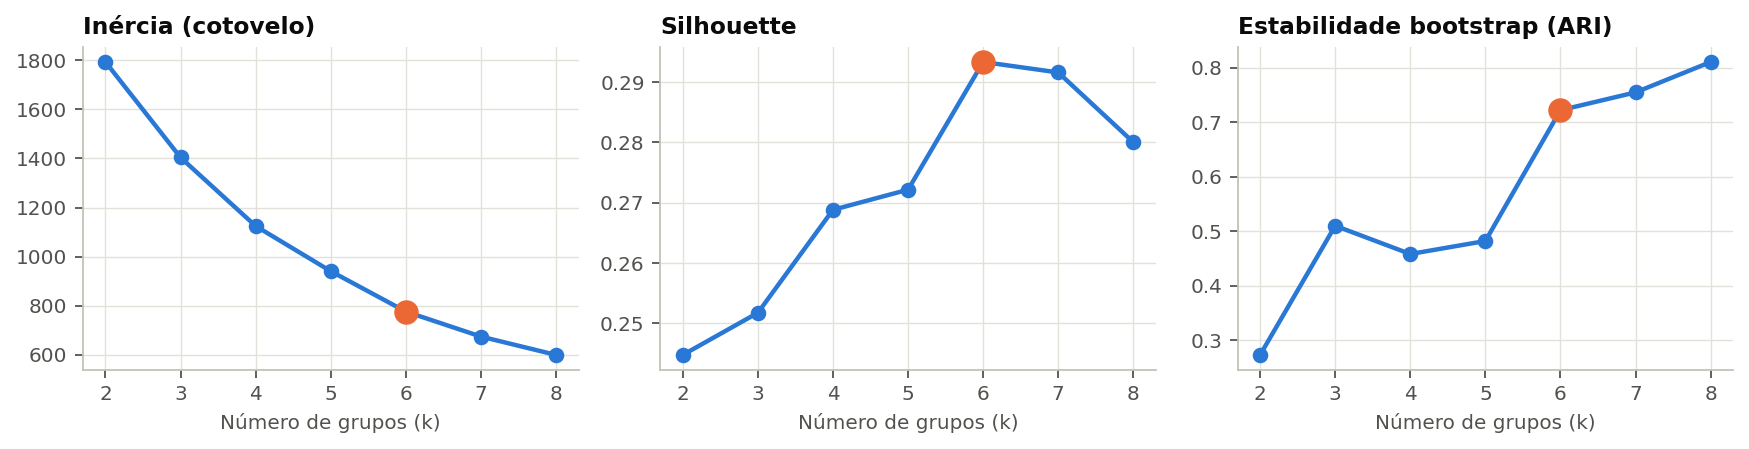

In [13]:
scaler_seg = preparo_segmentacao().fit(df_eda[SEG])
Z = scaler_seg.transform(df_eda[SEG])
rng = np.random.default_rng(SEED)
linhas = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Z)
    aris = []
    for b in range(20):
        idx = rng.choice(len(Z), len(Z), replace=True)
        prep_b = preparo_segmentacao().fit(df_eda[SEG].iloc[idx])
        zb = prep_b.transform(df_eda[SEG].iloc[idx])
        km_b = KMeans(n_clusters=k, n_init=10, random_state=b).fit(zb)
        aris.append(adjusted_rand_score(km.labels_, km_b.predict(prep_b.transform(df_eda[SEG]))))
    linhas.append({'k': k, 'inércia': km.inertia_, 'silhouette': silhouette_score(Z, km.labels_),
                   'Davies-Bouldin': davies_bouldin_score(Z, km.labels_), 'estabilidade (ARI)': np.mean(aris)})
tab_k = pd.DataFrame(linhas).set_index('k')
display(tab_k.round(3))
K = int(tab_k['silhouette'].idxmax())
print(f'k escolhido (maior silhouette): {K}')

fig, axs = plt.subplots(1, 3, figsize=(11, 2.9))
for a, col, titulo in zip(axs, ['inércia', 'silhouette', 'estabilidade (ARI)'],
                          ['Inércia (cotovelo)', 'Silhouette', 'Estabilidade bootstrap (ARI)']):
    a.plot(tab_k.index, tab_k[col], marker='o', ms=6, color=AZUL)
    a.plot(K, tab_k.loc[K, col], marker='o', ms=10, color=LARANJA, zorder=3)
    a.set_title(titulo); a.set_xlabel('Número de grupos (k)')
salvar(fig, 'fig07_escolha_k.png')
RES['k'] = K
RES['tab_k'] = tab_k.round(3).reset_index().to_dict(orient='records')


### 2.3 Perfis encontrados
Os grupos são numerados de **G1 (maior churn) a G6 (menor churn)** e descritos pela posição do centro de cada grupo em relação à média do treino nas três variáveis da segmentação: tickets (média de 4,37), frequência de acesso (3,47) e meses de contrato (24,3). Assim, "muitos tickets" significa acima da média do treino, e não um valor absoluto.

O churn **não participa do agrupamento**: as taxas são calculadas depois, só para ordenar e interpretar os grupos. Médias, categorias e taxas são calculadas **no treino**; a coluna de clientes no teste informa apenas quantos receberam cada grupo. As ações sugeridas são hipóteses a testar com grupo de controle.

In [14]:
kmeans = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(Z)
df['cluster'] = kmeans.predict(scaler_seg.transform(df[SEG]))
df_eda['cluster'] = df.loc[X_tr.index, 'cluster']
centros = df_eda.groupby('cluster')[SEG].mean()
medias_tr = df_eda[SEG].mean()          # referência para descrever cada grupo

# Numeração G1..GK do maior para o menor churn observado no treino.
# O churn NÃO participa do agrupamento; é usado só para ordenar e interpretar os grupos.
ordem_clusters = df_eda.groupby('cluster')[ALVO].mean().sort_values(ascending=False).index

def descrever(c):
    """Descreve o centro do grupo em relação à média do treino nas três variáveis da segmentação."""
    return ', '.join(['muitos tickets' if c.Tickets_Suporte >= medias_tr.Tickets_Suporte else 'poucos tickets',
                      'uso alto' if c.Frequencia_Acesso_Semanal >= medias_tr.Frequencia_Acesso_Semanal else 'uso baixo',
                      'contrato longo' if c.Meses_Contrato >= medias_tr.Meses_Contrato else 'contrato curto'])

def acao(c):
    """Hipótese de abordagem (a testar com grupo de controle) conforme suporte e uso."""
    muitos_tickets = c.Tickets_Suporte >= medias_tr.Tickets_Suporte
    uso_alto = c.Frequencia_Acesso_Semanal >= medias_tr.Frequencia_Acesso_Semanal
    if muitos_tickets and not uso_alto:
        return 'Recuperação pelo suporte: contato proativo para resolver chamados e entender o motivo; oferta só após resolver'
    if muitos_tickets:
        return 'Suporte técnico prioritário: corrigir falhas de app/dispositivo e acompanhar o cliente após o chamado'
    if not uso_alto:
        return 'Reengajamento: recomendações pelo gênero favorito e avisos de lançamentos'
    return 'Fidelização: benefícios por permanência; evitar desconto genérico (baixo risco)'

nomes, ACOES = {}, {}
for n, cl in enumerate(ordem_clusters, start=1):
    nome = f'G{n} {descrever(centros.loc[cl])}'
    nomes[cl] = nome
    ACOES[nome] = acao(centros.loc[cl])
if len({n.split(' ', 1)[1] for n in nomes.values()}) < K:
    print('Aviso: há grupos com a mesma descrição; diferencie-os pelo código G.')

df['Persona'] = df.cluster.map(nomes); df_eda['Persona'] = df_eda.cluster.map(nomes)
def moda_seg(s):
    m = s.dropna().mode(); return m.iloc[0] if len(m) else 'Não informado'
perfil = df_eda.groupby('Persona').agg(
    clientes=('ID_Cliente', 'size'), acessos_semana=('Frequencia_Acesso_Semanal', 'mean'),
    tickets=('Tickets_Suporte', 'mean'), meses_contrato=('Meses_Contrato', 'mean'),
    mensalidade=('Valor_Mensal', 'mean'), taxa_churn=(ALVO, 'mean'),
    genero_mais_comum=('Genero_Favorito', moda_seg), dispositivo_mais_comum=('Dispositivo_Principal', moda_seg),
    plano_mais_comum=('Plano', moda_seg)).sort_values('taxa_churn', ascending=False)
perfil['clientes_teste'] = df.loc[X_te.index, 'Persona'].value_counts().reindex(perfil.index, fill_value=0)
perfil['proporcao_treino'] = perfil.clientes / len(X_tr)
perfil['ação sugerida'] = [ACOES[n] for n in perfil.index]
print('Médias do treino usadas como referência:', medias_tr.round(2).to_dict())
display(perfil.round(3)); perfil.to_csv(PASTA / 'perfis_personas.csv', encoding='utf-8-sig')
RES['personas'] = perfil.round(4).reset_index().to_dict(orient='records')
RES['silhouette_k'] = float(tab_k.loc[K, 'silhouette']); RES['ari_k'] = float(tab_k.loc[K, 'estabilidade (ARI)'])

Médias do treino usadas como referência: {'Frequencia_Acesso_Semanal': 3.47, 'Tickets_Suporte': 4.37, 'Meses_Contrato': 24.31}


,clientes,acessos_semana,tickets,meses_contrato,mensalidade,taxa_churn,genero_mais_comum,dispositivo_mais_comum,plano_mais_comum,clientes_teste,proporcao_treino,ação sugerida
Persona,,,,,,,,,,,,
"G1 muitos tickets, uso baixo, contrato curto",127,1.299,7.039,14.512,43.931,1.000,Documentarios,Web,Standard,29,0.159,Recuperação pelo suporte: contato proativo para resolver chamados e entender o motivo; oferta só após resolver
"G2 muitos tickets, uso baixo, contrato longo",132,3.409,7.197,37.652,44.475,0.970,Documentarios,Web,Standard,40,0.165,Recuperação pelo suporte: contato proativo para resolver chamados e entender o motivo; oferta só após resolver
"G3 muitos tickets, uso alto, contrato curto",124,5.629,6.234,12.202,45.233,0.726,Desporto,Mobile,Basico,36,0.155,Suporte técnico prioritário: corrigir falhas de app/dispositivo e acompanhar o cliente após o chamado
"G4 poucos tickets, uso baixo, contrato longo",131,1.695,2.145,36.771,45.651,0.366,Filmes,Smart TV,Premium,21,0.164,Reengajamento: recomendações pelo gênero favorito e avisos de lançamentos
"G5 poucos tickets, uso baixo, contrato curto",116,2.155,1.647,11.448,46.308,0.276,Filmes,Smart TV,Premium,32,0.145,Reengajamento: recomendações pelo gênero favorito e avisos de lançamentos
"G6 poucos tickets, uso alto, contrato longo",170,5.829,2.406,29.265,45.173,0.053,Desporto,Web,Basico,42,0.212,Fidelização: benefícios por permanência; evitar desconto genérico (baixo risco)


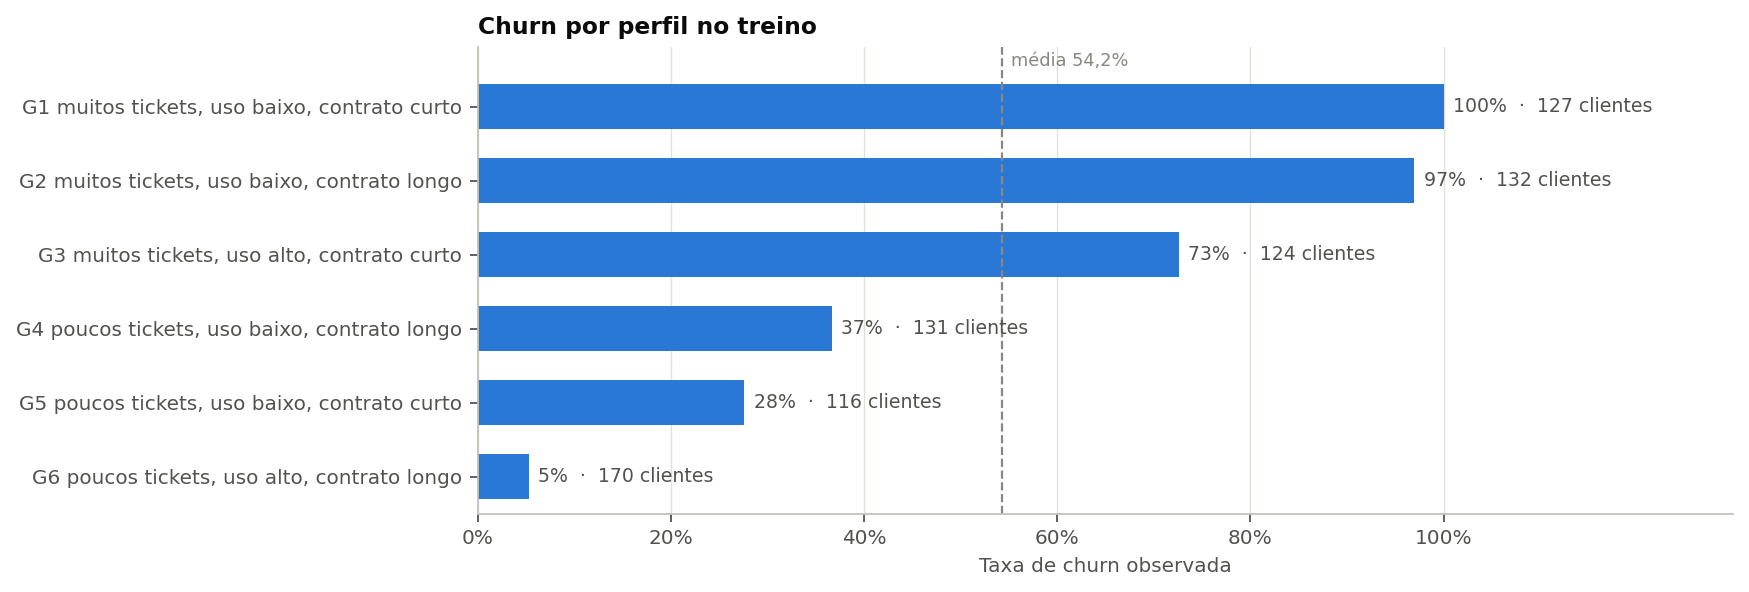

In [15]:
fig, ax = plt.subplots(figsize=(11, 3.8))
p = perfil.sort_values('taxa_churn')
barras = ax.barh(p.index, p['taxa_churn'], color=AZUL, height=0.6)
ax.axvline(taxa_churn, color=MUDO, ls='--', lw=1)
ax.text(taxa_churn + 0.01, len(p) - 0.45, f'média {pct(taxa_churn)}', color=MUDO, fontsize=8)
ax.set_ylim(-0.5, len(p) - 0.2)
for b, (n, row) in zip(barras, p.iterrows()):
    ax.text(b.get_width() + 0.01, b.get_y() + b.get_height() / 2,
            f"{pct(row['taxa_churn'], 0)}  ·  {int(row['clientes'])} clientes", va='center', fontsize=8.5, color=TINTA2)
ax.set_xlim(0, 1.3); ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0]); ax.set_xlabel('Taxa de churn observada'); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('Churn por perfil no treino')
salvar(fig, 'fig10_personas_churn.png')


### 2.4 Visualização via PCA
A PCA é ajustada nos dados de treino já imputados e padronizados. As projeções mostram somente o treino e apresentam a variância preservada. O K-Means opera nas três variáveis preparadas, não no gráfico de duas dimensões. A orientação dos eixos é arbitrária; cores pelo alvo servem apenas à interpretação posterior.


Variância explicada: ['35,5%', '33,3%', '31,3%'] | PC1+PC2 = 68,7%
PCA nas 4 numéricas → ['26,7%', '26,0%', '24,9%', '22,4%']


,PC1,PC2,PC3
Frequencia_Acesso_Semanal,-0.350,0.883,0.314
Tickets_Suporte,0.701,0.024,0.713
Meses_Contrato,-0.622,-0.470,0.627


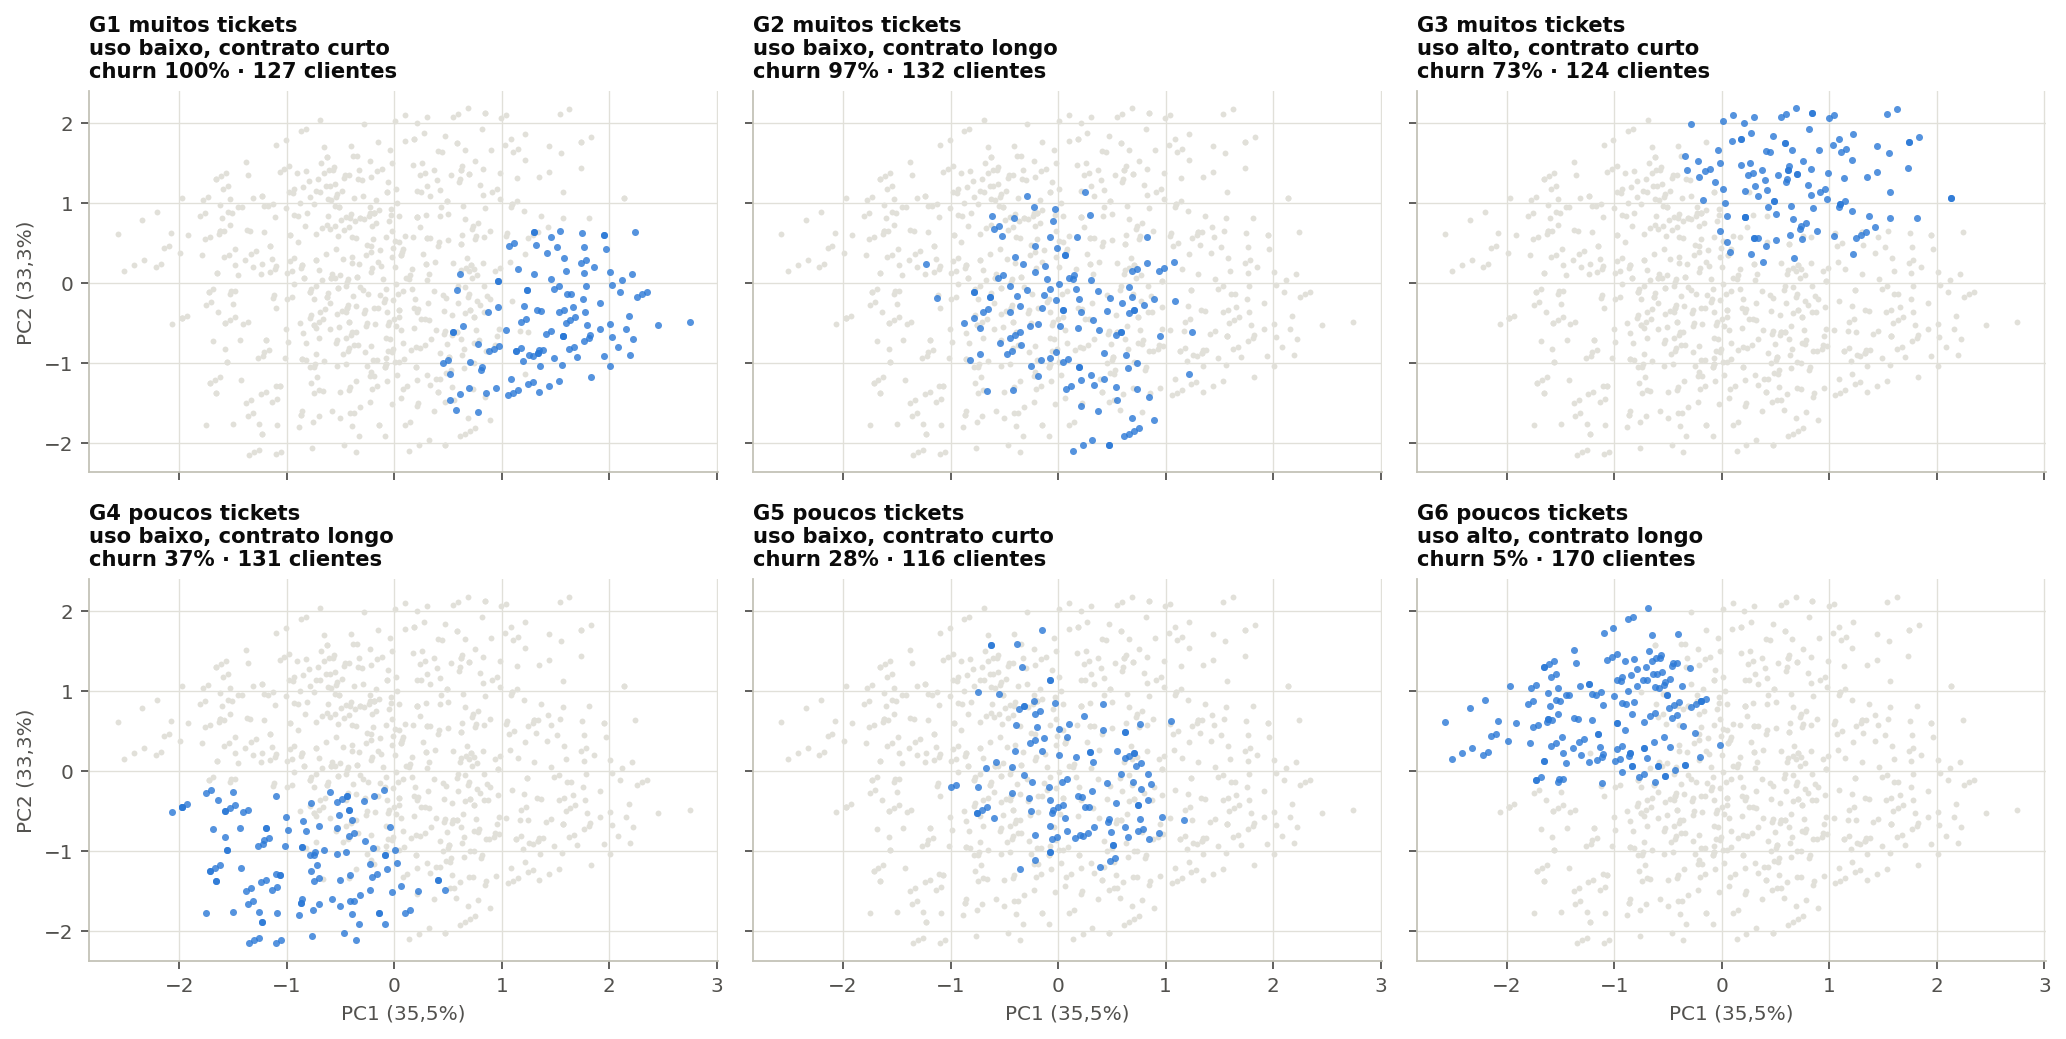

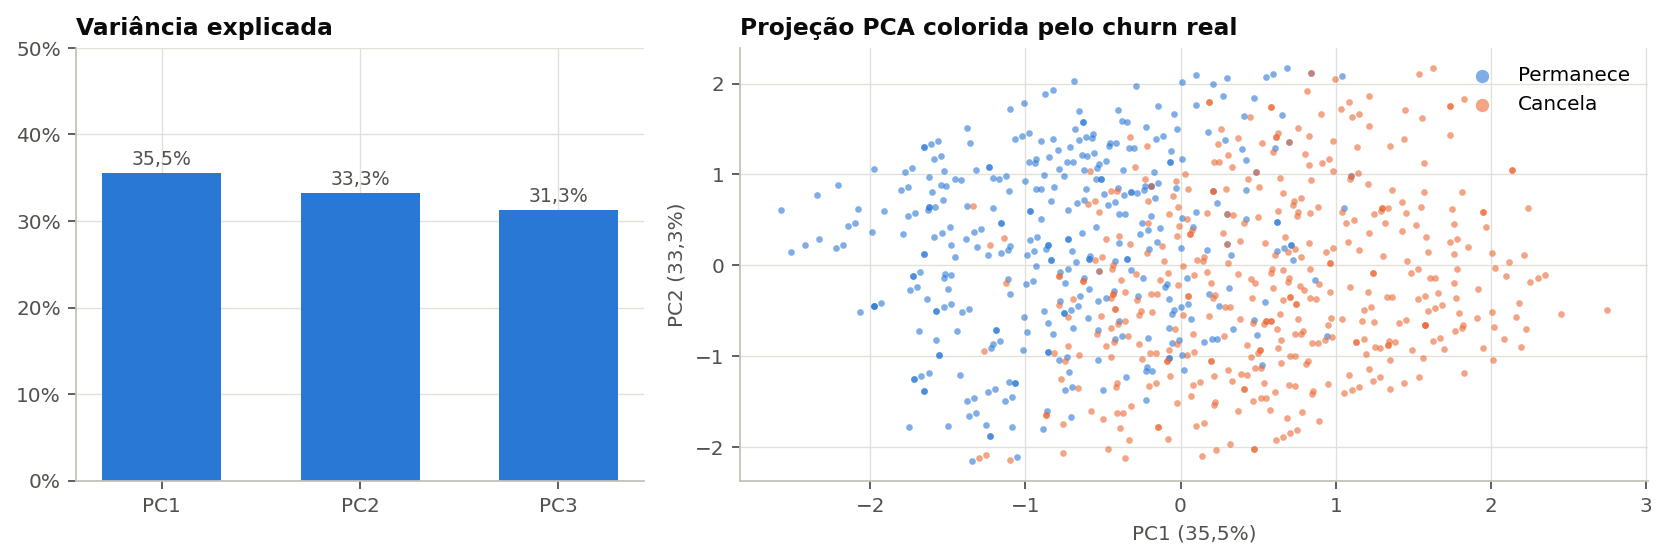

In [16]:
pca = PCA(n_components=3, random_state=SEED).fit(Z)
coords = pca.transform(Z)
var = pca.explained_variance_ratio_
loadings = pd.DataFrame(pca.components_.T, index=SEG, columns=['PC1', 'PC2', 'PC3'])
print('Variância explicada:', [pct(v) for v in var], '| PC1+PC2 =', pct(var[:2].sum()))
display(loadings.round(3))

# PCA com todas as numéricas: verifica se existe estrutura de baixa dimensão na base
var_todas = PCA().fit(preparo_segmentacao().fit_transform(df_eda[NUM])).explained_variance_ratio_
print('PCA nas 4 numéricas →', [pct(v) for v in var_todas])

ordem_p = perfil.index.tolist()
linhas_fig = int(np.ceil(K / 3))
fig, axs = plt.subplots(linhas_fig, 3, figsize=(13, 3.3 * linhas_fig), sharex=True, sharey=True, squeeze=False)
for a, nome in zip(axs.ravel(), ordem_p):
    m = (df_eda['Persona'] == nome).to_numpy()
    a.scatter(coords[~m, 0], coords[~m, 1], s=7, color='#e1e0d9', linewidths=0)
    a.scatter(coords[m, 0], coords[m, 1], s=10, color=AZUL, alpha=0.8, linewidths=0)
    titulo = nome.replace(', ', '\n', 1)          # quebra o nome em duas linhas
    a.set_title(f"{titulo}\nchurn {pct(perfil.loc[nome, 'taxa_churn'], 0)} · {int(perfil.loc[nome, 'clientes'])} clientes", fontsize=9.5)
for a in axs[-1]: a.set_xlabel(f'PC1 ({pct(var[0])})')
for a in axs[:, 0]: a.set_ylabel(f'PC2 ({pct(var[1])})')
for a in axs.ravel()[len(ordem_p):]: a.set_visible(False)
salvar(fig, 'fig08_pca_personas.png')

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={'width_ratios': [1, 1.6]})
axs[0].bar(['PC1', 'PC2', 'PC3'], var, color=AZUL, width=0.6)
for i, v in enumerate(var): axs[0].text(i, v + 0.01, pct(v), ha='center', fontsize=8.5, color=TINTA2)
axs[0].set_title('Variância explicada'); axs[0].set_ylim(0, 0.5)
axs[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
for valor, cor, nome in [(0, AZUL, 'Permanece'), (1, LARANJA, 'Cancela')]:
    m = (df_eda[ALVO] == valor).to_numpy()
    axs[1].scatter(coords[m, 0], coords[m, 1], s=9, color=cor, alpha=0.6, label=nome, linewidths=0)
axs[1].set(title='Projeção PCA colorida pelo churn real', xlabel=f'PC1 ({pct(var[0])})', ylabel=f'PC2 ({pct(var[1])})')
axs[1].legend(loc='upper right', markerscale=2)
salvar(fig, 'fig09_pca_variancia_churn.png')
RES['pca_var'] = [float(v) for v in var]; RES['pca_var_todas'] = [float(v) for v in var_todas]
RES['loadings'] = loadings.round(3).to_dict()


In [17]:
# Gêneros favoritos dentro de cada persona (% da linha) e teste de independência
cross = pd.crosstab(df_eda['Persona'], df_eda['Genero_Favorito'], normalize='index').reindex(ordem_p)
display((cross * 100).round(1).astype(str) + '%')
_, p_gen_persona, _, _ = chi2_contingency(pd.crosstab(df_eda['Persona'], df_eda['Genero_Favorito']))
_, p_disp_persona, _, _ = chi2_contingency(pd.crosstab(df_eda['Persona'], df_eda['Dispositivo_Principal']))
print(f'Qui² gênero × persona: p = {p_gen_persona:.3f} | dispositivo × persona: p = {p_disp_persona:.3f}')
RES['p_genero_persona'] = float(p_gen_persona); RES['p_disp_persona'] = float(p_disp_persona)


Qui² gênero × persona: p = 0.347 | dispositivo × persona: p = 0.189


Genero_Favorito,Desporto,Documentarios,Filmes,Series
Persona,,,,
"G1 muitos tickets, uso baixo, contrato curto",29.1%,30.7%,21.3%,18.9%
"G2 muitos tickets, uso baixo, contrato longo",25.0%,26.5%,22.7%,25.8%
"G3 muitos tickets, uso alto, contrato curto",30.6%,27.4%,20.2%,21.8%
"G4 poucos tickets, uso baixo, contrato longo",17.6%,24.4%,32.1%,26.0%
"G5 poucos tickets, uso baixo, contrato curto",20.7%,23.3%,30.2%,25.9%
"G6 poucos tickets, uso alto, contrato longo",26.5%,23.5%,26.5%,23.5%


**Interpretação dos perfis**
- **G1 e G2 — muitos tickets e uso baixo (churn de 100% e 97%).** Ambos têm uso abaixo da média e muitos tickets, mas diferem nas médias de contrato e frequência. A alta taxa de churn nesses grupos não permite concluir que contratos longos protejam ou causem cancelamento. Hipótese: recuperação pelo suporte antes de qualquer oferta.
- **G3 — muitos tickets e uso alto (73%).** Usa bastante o serviço, mas abre muitos chamados; hipótese de falhas técnicas. Suporte prioritário e acompanhamento após o chamado.
- **G4 e G5 — poucos tickets e uso baixo (37% e 28%).** Risco intermediário associado ao baixo uso; hipótese de reengajamento por conteúdo.
- **G6 — poucos tickets, uso alto e contrato longo (5%).** Grupo com menor churn observado; a utilidade de descontos ou benefícios precisa ser testada.

G1 a G3 reúnem 48% dos clientes do treino (383) e 79,5% dos cancelamentos (345 de 434). Não houve evidência estatística suficiente de associação de gênero (p = 0,35) ou dispositivo (p = 0,19) com os grupos: as personas são definidas por suporte, uso e contrato, não por preferência de conteúdo. O gênero mais comum não representa a maioria do grupo. A silhouette de 0,29 indica separação moderada a fraca; as personas são descrições estatísticas, não categorias permanentes de pessoas.

## 3. Classificação do churn registrado
### 3.1 Divisão dos dados e pipeline
O split estratificado de 80% treino e 20% teste foi feito antes da exploração e da segmentação. IDs e personas não são preditores. Os classificadores usam quatro variáveis numéricas e três categóricas, com imputação, escala e encoding reaprendidos no treino de cada dobra. O teste não define o modelo, os hiperparâmetros ou o limiar.


In [18]:
# Reutiliza a divisão antecipada da auditoria, sem redefinir o teste.
print(f'Treino: {len(X_tr)} clientes (churn {pct(y_tr.mean())}) | Teste: {len(X_te)} clientes (churn {pct(y_te.mean())})')

def preprocessador(num=NUM, cat=CAT):
    numericas = Pipeline([('imputacao', SimpleImputer(strategy='median')), ('escala', StandardScaler())])
    categoricas = Pipeline([('imputacao', SimpleImputer(strategy='most_frequent')),
                            ('onehot', OneHotEncoder(handle_unknown='ignore'))])
    return ColumnTransformer([('num', numericas, list(num)), ('cat', categoricas, list(cat))])

def pipeline(modelo, num=NUM, cat=CAT):
    return Pipeline([('preparo', preprocessador(num, cat)), ('modelo', modelo)])

RES['split'] = dict(treino=len(X_tr), teste=len(X_te), churn_treino=float(y_tr.mean()), churn_teste=float(y_te.mean()))


Treino: 800 clientes (churn 54,2%) | Teste: 200 clientes (churn 54,0%)


### 3.2 Candidatos e controle de complexidade
Comparamos os algoritmos exemplificados no enunciado: Random Forest, Gradient Boosting, SVM e k-NN. Dummy e Regressão Logística são referências. Esta restrição aos quatro candidatos principais é uma escolha didática, pois o enunciado não proíbe outros algoritmos.

Uma CV interna de cinco dobras escolhe hiperparâmetros e uma CV externa de cinco dobras estima desempenho. Profundidade, regularização, folhas e vizinhos controlam complexidade. A métrica de seleção é ROC AUC. A média do melhor candidato ainda está sujeita à seleção entre famílias; o teste reservado fornece a avaliação final. Desvios entre dobras não são intervalos de confiança.


In [19]:
CANDIDATOS = {
    'Dummy (referência)': (DummyClassifier(strategy='most_frequent'), {}),
    'Regressão Logística (referência)': (LogisticRegression(max_iter=2000), {'modelo__C': [0.01, 0.1, 1, 10]}),
    'k-NN': (KNeighborsClassifier(), {'modelo__n_neighbors': [5, 15, 25, 45], 'modelo__weights': ['uniform', 'distance']}),
    'SVM (RBF)': (SVC(probability=True, random_state=SEED), {'modelo__C': [0.1, 1, 10], 'modelo__gamma': ['scale', 0.03, 0.1]}),
    'Random Forest': (RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
                      {'modelo__max_depth': [3, 5, 8, None], 'modelo__min_samples_leaf': [1, 5, 15]}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=SEED, subsample=0.8),
                          {'modelo__n_estimators': [100, 200], 'modelo__learning_rate': [0.05, 0.1], 'modelo__max_depth': [2, 3]}),
}
cv_ext = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_int = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
METRICAS = {'auc': 'roc_auc', 'ap': 'average_precision', 'f1': 'f1', 'recall': 'recall', 'precisao': 'precision', 'acuracia': 'accuracy'}

def buscador(nome):
    modelo, grade = CANDIDATOS[nome]
    pipe = pipeline(clone(modelo))
    return GridSearchCV(pipe, grade, cv=cv_int, scoring='roc_auc', n_jobs=2, error_score='raise') if grade else pipe

linhas = []
for nome in CANDIDATOS:
    s = cross_validate(buscador(nome), X_tr, y_tr, cv=cv_ext, scoring=METRICAS, return_train_score=True, n_jobs=1)
    linhas.append({'modelo': nome, 'AUC treino': s['train_auc'].mean(), 'AUC CV': s['test_auc'].mean(), 'AUC CV dp': s['test_auc'].std(),
                   'AP CV': s['test_ap'].mean(), 'F1 CV': s['test_f1'].mean(), 'Recall CV': s['test_recall'].mean(),
                   'Precisão CV': s['test_precisao'].mean(), 'Acurácia CV': s['test_acuracia'].mean()})
    print(f"{nome:34s} AUC CV = {s['test_auc'].mean():.3f} ± {s['test_auc'].std():.3f}")
tab_cv = pd.DataFrame(linhas).set_index('modelo')
tab_cv['gap treino−CV'] = tab_cv['AUC treino'] - tab_cv['AUC CV']
display(tab_cv.round(3))
tab_cv.round(4).to_csv(PASTA / 'comparacao_modelos_cv.csv', encoding='utf-8-sig')


Dummy (referência)                 AUC CV = 0.500 ± 0.000
Regressão Logística (referência)   AUC CV = 0.977 ± 0.010
k-NN                               AUC CV = 0.971 ± 0.009
SVM (RBF)                          AUC CV = 0.973 ± 0.011
Random Forest                      AUC CV = 0.968 ± 0.012
Gradient Boosting                  AUC CV = 0.977 ± 0.010


,AUC treino,AUC CV,AUC CV dp,AP CV,F1 CV,Recall CV,Precisão CV,Acurácia CV,gap treino−CV
modelo,,,,,,,,,
Dummy (referência),0.500,0.500,0.000,0.542,0.703,1.000,0.542,0.542,0.000
Regressão Logística (referência),0.980,0.977,0.010,0.982,0.915,0.915,0.918,0.909,0.003
k-NN,0.980,0.971,0.009,0.976,0.916,0.915,0.920,0.910,0.009
SVM (RBF),0.982,0.973,0.011,0.978,0.908,0.901,0.917,0.901,0.010
Random Forest,0.992,0.968,0.012,0.973,0.906,0.906,0.909,0.899,0.023
Gradient Boosting,0.982,0.977,0.010,0.981,0.919,0.919,0.921,0.912,0.005


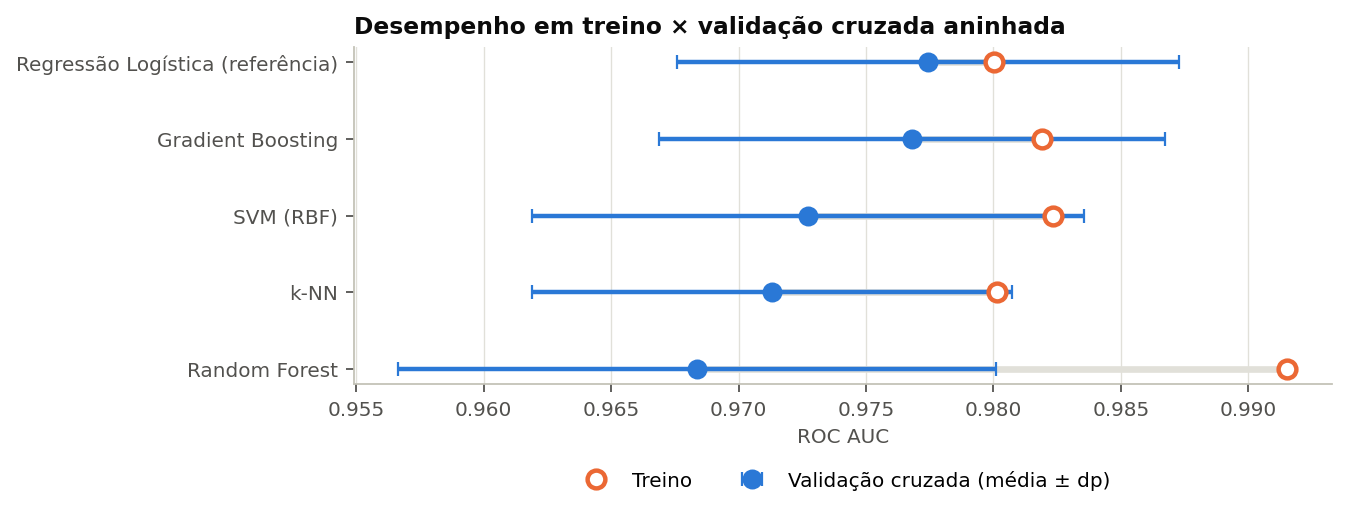

In [20]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
t = tab_cv.drop('Dummy (referência)').sort_values('AUC CV')
yy = np.arange(len(t))
ax.hlines(yy, t['AUC CV'], t['AUC treino'], color=GRADE, lw=3)
ax.errorbar(t['AUC CV'], yy, xerr=t['AUC CV dp'], fmt='o', ms=8, color=AZUL, ecolor=AZUL, capsize=3, label='Validação cruzada (média ± dp)')
ax.plot(t['AUC treino'], yy, 'o', ms=8, mfc='white', mec=LARANJA, mew=2, label='Treino')
ax.set_yticks(yy); ax.set_yticklabels(t.index); ax.grid(axis='y', visible=False)
ax.set_xlabel('ROC AUC'); ax.set_title('Desempenho em treino × validação cruzada aninhada')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
salvar(fig, 'fig11_comparacao_modelos.png')

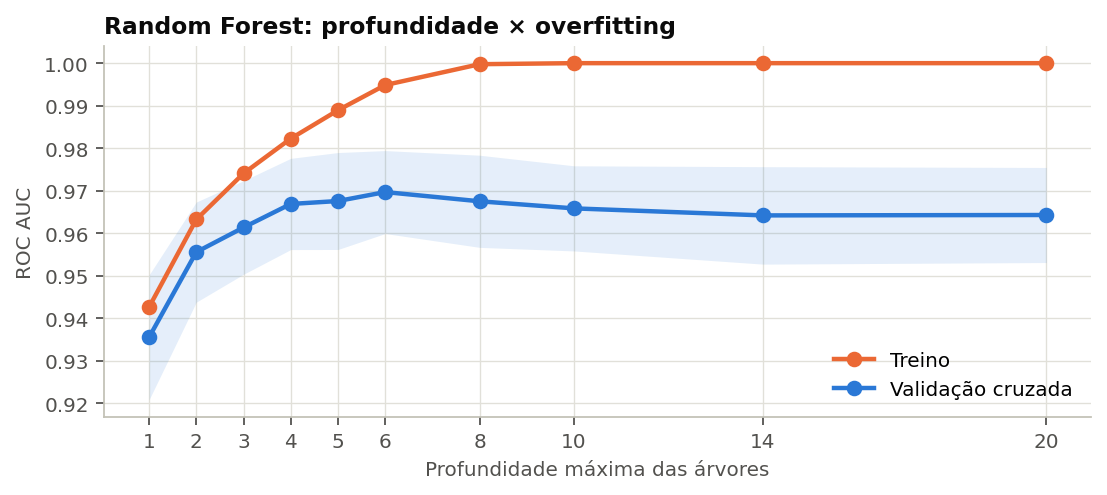

In [21]:
# Curva de validação: efeito da profundidade das árvores (Random Forest) no overfitting
profundidades = [1, 2, 3, 4, 5, 6, 8, 10, 14, 20]
tr_sc, va_sc = validation_curve(pipeline(RandomForestClassifier(n_estimators=200, min_samples_leaf=1, random_state=SEED, n_jobs=2)),
                                X_tr, y_tr, param_name='modelo__max_depth', param_range=profundidades,
                                cv=cv_ext, scoring='roc_auc', n_jobs=1)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(profundidades, tr_sc.mean(1), marker='o', ms=6, color=LARANJA, label='Treino')
ax.plot(profundidades, va_sc.mean(1), marker='o', ms=6, color=AZUL, label='Validação cruzada')
ax.fill_between(profundidades, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), color=AZUL, alpha=0.12, linewidth=0)
ax.set_xticks(profundidades)
ax.set(xlabel='Profundidade máxima das árvores', ylabel='ROC AUC', title='Random Forest: profundidade × overfitting')
ax.legend(loc='lower right')
salvar(fig, 'fig12_curva_validacao_rf.png')
RES['curva_rf'] = {'prof': profundidades, 'treino': tr_sc.mean(1).round(4).tolist(), 'cv': va_sc.mean(1).round(4).tolist()}


### 3.3 Escolha e ajuste final
Entre os quatro candidatos principais, escolhemos a maior AUC média da CV aninhada. Reajustamos a busca nos 800 clientes de treino. A Regressão Logística permanece como comparação de simplicidade; diferenças pequenas entre modelos não comprovam superioridade estatística. Não se troca o modelo depois de consultar o teste.


In [22]:
ELEGIVEIS = ['k-NN', 'SVM (RBF)', 'Random Forest', 'Gradient Boosting']
ESCOLHIDO = tab_cv.loc[ELEGIVEIS, 'AUC CV'].idxmax()
print(f'Modelo escolhido: {ESCOLHIDO} (AUC CV = {tab_cv.loc[ESCOLHIDO, "AUC CV"]:.3f})')

ajustados = {}
for nome in CANDIDATOS:
    b = buscador(nome).fit(X_tr, y_tr)
    ajustados[nome] = b.best_estimator_ if hasattr(b, 'best_estimator_') else b
    if hasattr(b, 'best_params_'):
        print(f'  {nome:34s} melhores hiperparâmetros: {b.best_params_}')
modelo_final = ajustados[ESCOLHIDO]
params_final = {k.replace('modelo__', ''): v for k, v in modelo_final.named_steps['modelo'].get_params().items()
                if 'modelo__' + k in CANDIDATOS[ESCOLHIDO][1]}
RES['escolhido'] = ESCOLHIDO; RES['params_final'] = {k: (None if v is None else v) for k, v in params_final.items()}
RES['tab_cv'] = tab_cv.round(4).reset_index().to_dict(orient='records')

Modelo escolhido: Gradient Boosting (AUC CV = 0.977)
  Regressão Logística (referência)   melhores hiperparâmetros: {'modelo__C': 0.1}
  k-NN                               melhores hiperparâmetros: {'modelo__n_neighbors': 45, 'modelo__weights': 'uniform'}
  SVM (RBF)                          melhores hiperparâmetros: {'modelo__C': 1, 'modelo__gamma': 0.03}
  Random Forest                      melhores hiperparâmetros: {'modelo__max_depth': 5, 'modelo__min_samples_leaf': 1}
  Gradient Boosting                  melhores hiperparâmetros: {'modelo__learning_rate': 0.05, 'modelo__max_depth': 2, 'modelo__n_estimators': 100}


In [23]:
# Teste de robustez do pipeline: cliente com dados faltando e categoria nunca vista
cliente_incompleto = pd.DataFrame([{'Meses_Contrato': np.nan, 'Valor_Mensal': 49.9, 'Frequencia_Acesso_Semanal': 1,
                                    'Tickets_Suporte': np.nan, 'Plano': 'Familia', 'Genero_Favorito': 'Series',
                                    'Dispositivo_Principal': np.nan}])
print('Probabilidade de churn estimada para um cliente incompleto:',
      f"{modelo_final.predict_proba(cliente_incompleto)[0, 1]:.3f} (o pipeline imputou e ignorou a categoria nova sem erro)")

Probabilidade de churn estimada para um cliente incompleto: 0.818 (o pipeline imputou e ignorou a categoria nova sem erro)


## 4. Avaliação
### 4.1 Precisão e recall com custos ilustrativos
Precisão é VP/(VP+FP); recall é VP/(VP+FN). F1 combina ambas e acurácia mede a proporção de acertos. ROC AUC avalia a ordenação dos escores através de limiares; AP resume precisão-recall e não equivale à área trapezoidal.

Para o exercício, C = 0,5 × soma dos valores mensais dos FP + 3 × soma dos valores mensais dos FN. A razão é seis **para clientes de mesmo valor mensal**. A moeda não foi confirmada: usamos unidades monetárias hipotéticas. A função omite custo dos contatos corretos e eficácia da oferta; não calcula lucro, ROI ou cancelamentos evitados.

O limiar minimiza o custo em escores out-of-fold do treino. **A busca de hiperparâmetros é refeita dentro de cada dobra**, evitando que a escolha dos parâmetros use o rótulo da observação pontuada. A família foi selecionada no treino; o OOF é instrumento de ajuste, não avaliação final independente. Incluem-se as políticas contatar todos e ninguém na grade.

Mensalidades inválidas ou ausentes interrompem o cálculo de custo com uma mensagem explícita. A imputação do classificador não fornece, por si só, valores monetários válidos para a avaliação econômica.


Limiar ótimo no treino (out-of-fold): 0,17
Custo no treino → limiar 0,50: u.m. 5.651,99 | limiar 0,17: u.m. 2.610,10


,limiar teórico 1/(1+razão),limiar ótimo (treino OOF),recall,precisão,% da base contatada
custo FN / custo FP,,,,,
1,0.500,0.52,0.915,0.930,0.534
2,0.333,0.33,0.961,0.882,0.591
4,0.200,0.17,0.995,0.811,0.666
6,0.143,0.17,0.995,0.811,0.666
10,0.091,0.17,0.995,0.811,0.666
20,0.048,0.17,0.995,0.811,0.666


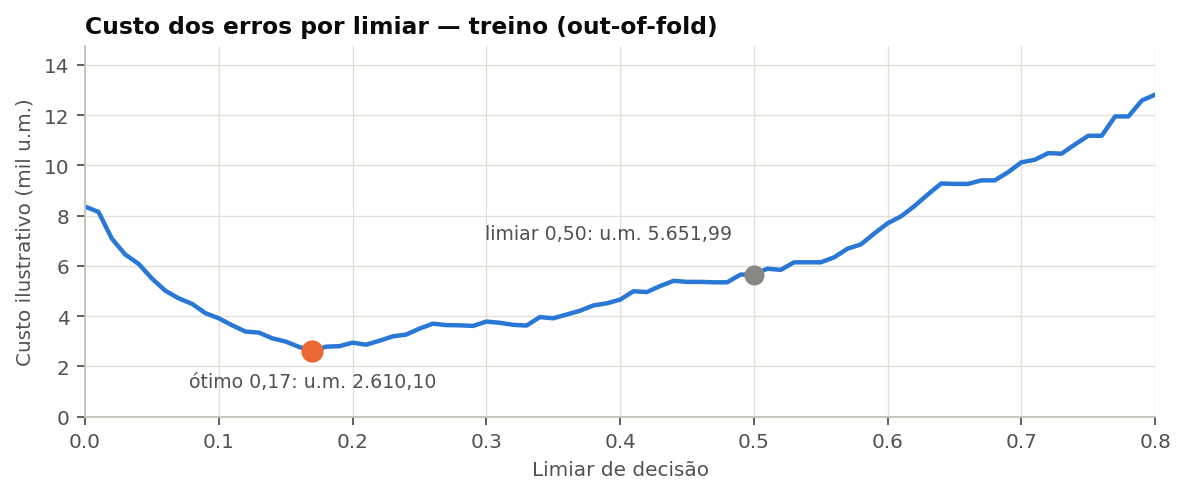

In [24]:
C_FP, C_FN = 0.5, 3.0          # múltiplos da mensalidade do próprio cliente
LIMIARES = np.r_[np.round(np.arange(0,1.01,0.01),2),1.01]

def custo(y_real, prob, valor, t, c_fp=C_FP, c_fn=C_FN):
    y_real, prob, valor = np.asarray(y_real), np.asarray(prob), np.asarray(valor, dtype=float)
    if y_real.ndim != 1 or prob.ndim != 1 or valor.ndim != 1 or not (len(y_real) == len(prob) == len(valor)):
        raise ValueError('Alvo, escore e mensalidade devem ser vetores de mesmo tamanho.')
    if not np.isfinite(valor).all() or (valor <= 0).any():
        raise ValueError('Custo exige mensalidades finitas e positivas; corrija ou documente a política para valores ausentes.')
    if not np.isin(y_real, [0, 1]).all() or not np.isfinite(prob).all() or ((prob < 0) | (prob > 1)).any():
        raise ValueError('Alvo deve ser 0/1 e escores devem estar entre 0 e 1.')
    if not np.isfinite([t, c_fp, c_fn]).all() or min(c_fp, c_fn) < 0:
        raise ValueError('Limiar e custos devem ser finitos e os custos não negativos.')
    prev = prob >= t
    return c_fp * valor[prev & (y_real == 0)].sum() + c_fn * valor[~prev & (y_real == 1)].sum()

def melhor_limiar(y_real, prob, valor, c_fp=C_FP, c_fn=C_FN):
    custos = np.array([custo(y_real, prob, valor, t, c_fp, c_fn) for t in LIMIARES])
    return float(LIMIARES[np.argmin(custos)]), custos      # empate → menor limiar (mais recall)

p_oof = cross_val_predict(buscador(ESCOLHIDO), X_tr, y_tr, cv=cv_ext, method='predict_proba')[:, 1]
valor_tr = X_tr['Valor_Mensal'].to_numpy()
T_OTIMO, custos_tr = melhor_limiar(y_tr, p_oof, valor_tr)
custo_05_tr = custo(y_tr, p_oof, valor_tr, 0.5)
print(f'Limiar ótimo no treino (out-of-fold): {num(T_OTIMO)}')
print(f'Custo no treino → limiar 0,50: {brl(custo_05_tr)} | limiar {num(T_OTIMO)}: {brl(custos_tr.min())}')

# Sensibilidade: proporção custo FN / custo FP
sens = []
for razao in [1, 2, 4, 6, 10, 20]:
    t, c = melhor_limiar(y_tr, p_oof, valor_tr, c_fp=0.5, c_fn=0.5 * razao)
    prev = p_oof >= t
    sens.append({'custo FN / custo FP': razao, 'limiar teórico 1/(1+razão)': round(1 / (1 + razao), 3),
                 'limiar ótimo (treino OOF)': t, 'recall': recall_score(y_tr, prev), 'precisão': precision_score(y_tr, prev),
                 '% da base contatada': prev.mean()})
tab_sens = pd.DataFrame(sens).set_index('custo FN / custo FP')
display(tab_sens.round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
m80 = LIMIARES <= 0.8
ax.plot(LIMIARES[m80], custos_tr[m80] / 1000, color=AZUL)
ax.set_ylim(0, custos_tr[m80].max() / 1000 * 1.15); ax.set_xlim(0, 0.8)
ax.plot(0.5, custo_05_tr / 1000, 'o', ms=8, color=MUDO)
ax.annotate(f'limiar 0,50: {brl(custo_05_tr)}', (0.5, custo_05_tr / 1000), xytext=(-10, 16), textcoords='offset points', ha='right', color=TINTA2, fontsize=8.5)
ax.plot(T_OTIMO, custos_tr.min() / 1000, 'o', ms=9, color=LARANJA)
ax.annotate(f'ótimo {num(T_OTIMO)}: {brl(custos_tr.min())}', (T_OTIMO, custos_tr.min() / 1000), xytext=(0, -16), textcoords='offset points', ha='center', color=TINTA2, fontsize=8.5)
ax.set(xlabel='Limiar de decisão', ylabel='Custo ilustrativo (mil u.m.)', title='Custo dos erros por limiar — treino (out-of-fold)')
salvar(fig, 'fig13_custo_limiar.png')
RES['limiar'] = T_OTIMO; RES['custo_treino'] = dict(t05=float(custo_05_tr), totimo=float(custos_tr.min()))
RES['sensibilidade'] = tab_sens.round(4).reset_index().to_dict(orient='records')


### 4.2 Teste reservado
Somente agora os rótulos de teste são usados para medir desempenho. Os candidatos aparecem em 0,50 e o escolhido também no limiar definido pelo treino. Comparações posteriores são diagnósticas: não motivam nova seleção. O intervalo bootstrap da AUC mantém o modelo fixo e mede variação do conjunto de teste, não instabilidade de retreinamento.


In [25]:
def metricas(y_real, prob, t=0.5):
    prev = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, prev, labels=[0, 1]).ravel()
    return {'acurácia': accuracy_score(y_real, prev), 'precisão': precision_score(y_real, prev, zero_division=0),
            'recall': recall_score(y_real, prev), 'F1': f1_score(y_real, prev), 'ROC AUC': roc_auc_score(y_real, prob),
            'AP': average_precision_score(y_real, prob), 'VP': tp, 'FP': fp, 'FN': fn, 'VN': tn}

prob_te = {nome: m.predict_proba(X_te)[:, 1] for nome, m in ajustados.items()}
linhas = [{'modelo': f'{n} · t=0,50', **metricas(y_te, p)} for n, p in prob_te.items()]
linhas.append({'modelo': f'{ESCOLHIDO} · t={num(T_OTIMO)}', **metricas(y_te, prob_te[ESCOLHIDO], T_OTIMO)})
tab_teste = pd.DataFrame(linhas).set_index('modelo')
display(tab_teste.round(3))
tab_teste.round(4).to_csv(PASTA / 'metricas_teste.csv', encoding='utf-8-sig')

p_final = prob_te[ESCOLHIDO]
print(f'\nRelatório de classificação — {ESCOLHIDO}, limiar {num(T_OTIMO)}:')
print(classification_report(y_te, (p_final >= T_OTIMO).astype(int), target_names=['Permanece', 'Cancela'], digits=3))

# Intervalo de confiança (bootstrap) da AUC no teste
rng = np.random.default_rng(SEED); aucs = []
yt = y_te.to_numpy()
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    if len(np.unique(yt[i])) == 2: aucs.append(roc_auc_score(yt[i], p_final[i]))
ic = np.quantile(aucs, [0.025, 0.975])
print(f'AUC no teste = {num(roc_auc_score(y_te, p_final), 3)} (IC 95% bootstrap: {num(ic[0], 3)} a {num(ic[1], 3)})')
RES['teste'] = tab_teste.round(4).reset_index().to_dict(orient='records')
RES['teste_05'] = {k: float(v) for k, v in metricas(y_te, p_final, 0.5).items()}
RES['teste_otimo'] = {k: float(v) for k, v in metricas(y_te, p_final, T_OTIMO).items()}
RES['auc_ic'] = [float(ic[0]), float(ic[1])]


Relatório de classificação — Gradient Boosting, limiar 0,17:
              precision    recall  f1-score   support

   Permanece      1.000     0.772     0.871        92
     Cancela      0.837     1.000     0.911       108

    accuracy                          0.895       200
   macro avg      0.919     0.886     0.891       200
weighted avg      0.912     0.895     0.893       200

AUC no teste = 0,982 (IC 95% bootstrap: 0,963 a 0,994)


,acurácia,precisão,recall,F1,ROC AUC,AP,VP,FP,FN,VN
modelo,,,,,,,,,,
"Dummy (referência) · t=0,50",0.540,0.540,1.000,0.701,0.500,0.540,108,92,0,0
"Regressão Logística (referência) · t=0,50",0.930,0.935,0.935,0.935,0.984,0.986,101,7,7,85
"k-NN · t=0,50",0.925,0.943,0.917,0.930,0.981,0.983,99,6,9,86
"SVM (RBF) · t=0,50",0.930,0.935,0.935,0.935,0.984,0.985,101,7,7,85
"Random Forest · t=0,50",0.930,0.927,0.944,0.936,0.976,0.975,102,8,6,84
"Gradient Boosting · t=0,50",0.940,0.936,0.954,0.945,0.982,0.982,103,7,5,85
"Gradient Boosting · t=0,17",0.895,0.837,1.000,0.911,0.982,0.982,108,21,0,71


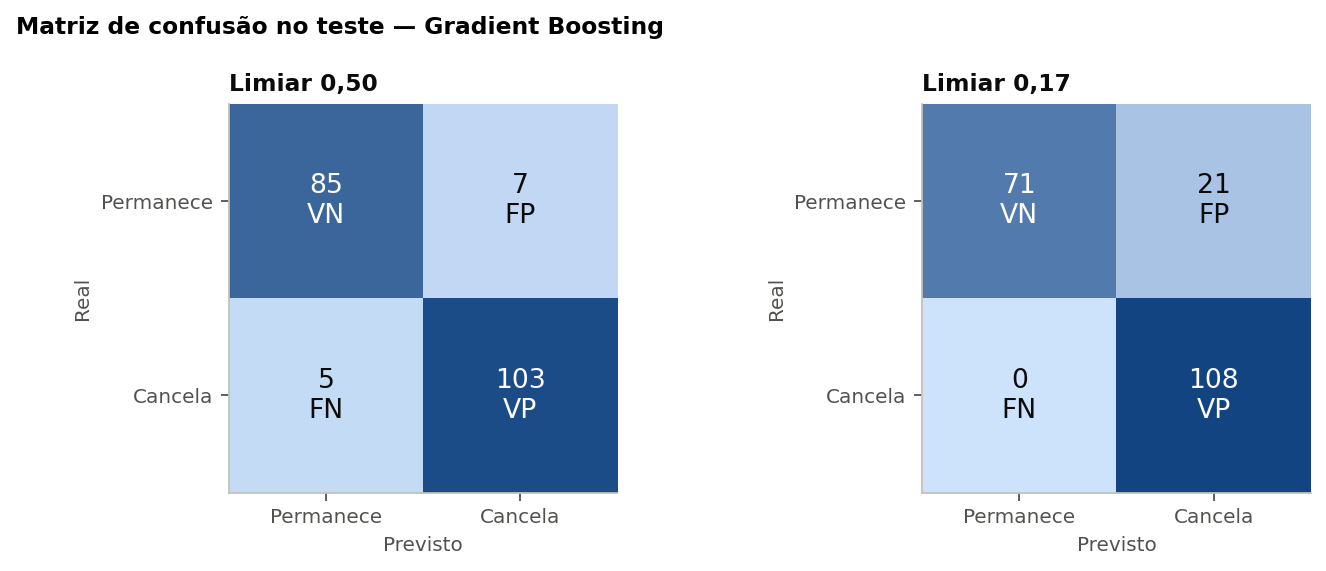

In [26]:
cmap_seq = LinearSegmentedColormap.from_list('seq', ['#cde2fb', '#104281'])
fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
for a, t in zip(axs, [0.5, T_OTIMO]):
    cm = confusion_matrix(y_te, (p_final >= t).astype(int), labels=[0, 1])
    a.imshow(cm, cmap=cmap_seq, vmin=0, vmax=len(y_te) * 0.55); a.grid(False)
    for i in range(2):
        for j in range(2):
            rot = [['VN', 'FP'], ['FN', 'VP']][i][j]
            a.text(j, i, f'{cm[i, j]}\n{rot}', ha='center', va='center', fontsize=12,
                   color='white' if cm[i, j] > len(y_te) * 0.3 else TINTA)
    a.set_xticks([0, 1]); a.set_xticklabels(['Permanece', 'Cancela']); a.set_yticks([0, 1]); a.set_yticklabels(['Permanece', 'Cancela'])
    a.set(xlabel='Previsto', ylabel='Real', title=f'Limiar {num(t)}')
fig.suptitle(f'Matriz de confusão no teste — {ESCOLHIDO}', x=0.02, ha='left', fontweight='bold', fontsize=10.5)
salvar(fig, 'fig14_matrizes_confusao.png')

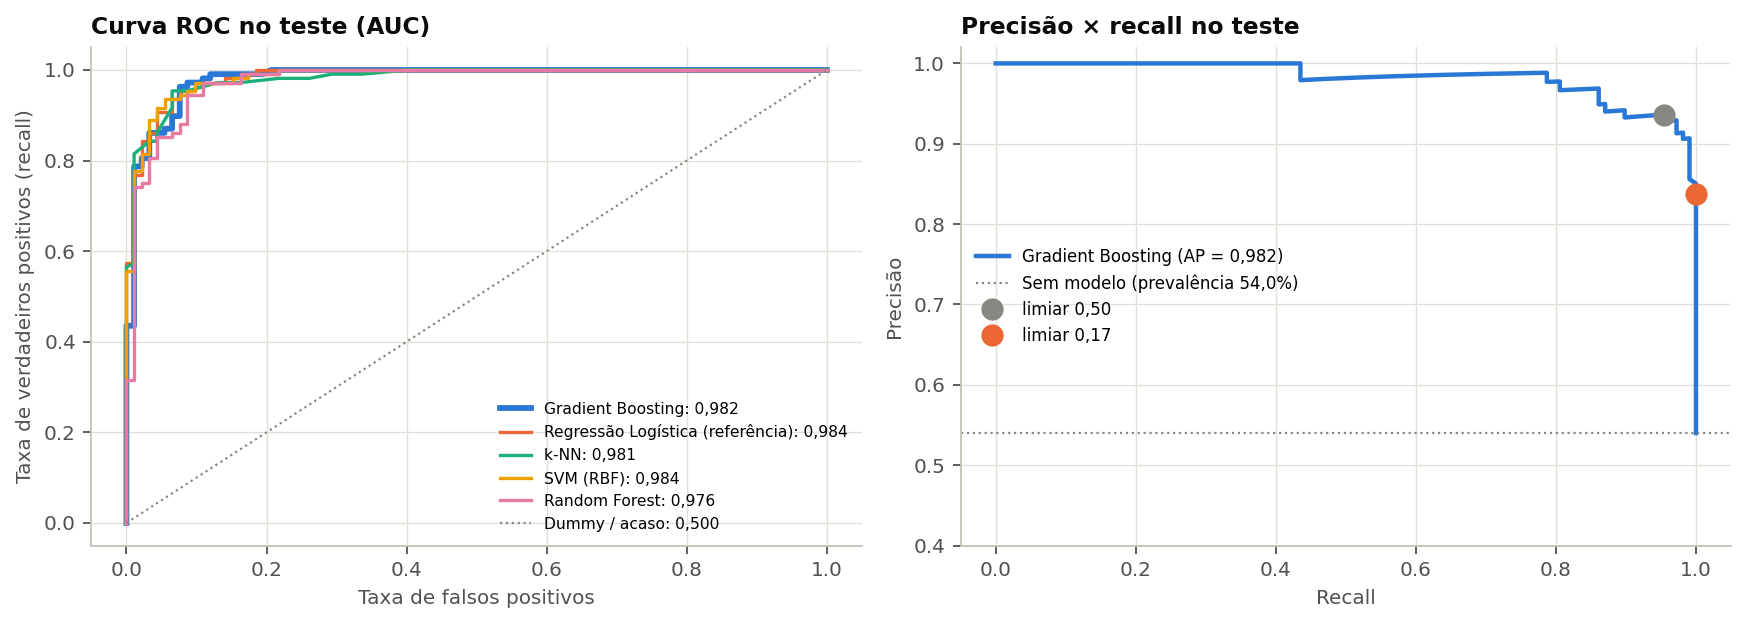

In [27]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ordem_modelos = [ESCOLHIDO] + [n for n in prob_te if n not in (ESCOLHIDO, 'Dummy (referência)')]
for cor, nome in zip(SERIES, ordem_modelos):
    fpr, tpr, _ = roc_curve(y_te, prob_te[nome])
    axs[0].plot(fpr, tpr, color=cor, lw=2.6 if nome == ESCOLHIDO else 1.5,
                label=f'{nome}: {num(roc_auc_score(y_te, prob_te[nome]), 3)}')
axs[0].plot([0, 1], [0, 1], ls=':', color=MUDO, lw=1, label='Dummy / acaso: 0,500')
axs[0].set(xlabel='Taxa de falsos positivos', ylabel='Taxa de verdadeiros positivos (recall)', title='Curva ROC no teste (AUC)')
axs[0].legend(loc='lower right', fontsize=7, bbox_to_anchor=(1.0, 0.0))
prec, rec, thr = precision_recall_curve(y_te, p_final)
axs[1].plot(rec, prec, color=AZUL, label=f'{ESCOLHIDO} (AP = {num(average_precision_score(y_te, p_final), 3)})')
axs[1].axhline(y_te.mean(), color=MUDO, ls=':', lw=1, label=f'Sem modelo (prevalência {pct(y_te.mean())})')
for t, cor in [(0.5, MUDO), (T_OTIMO, LARANJA)]:
    pv = (p_final >= t).astype(int)
    axs[1].plot(recall_score(y_te, pv), precision_score(y_te, pv), 'o', ms=9, color=cor, label=f'limiar {num(t)}')
axs[1].set(xlabel='Recall', ylabel='Precisão', title='Precisão × recall no teste', ylim=(0.4, 1.02))
axs[1].legend(loc='center left', fontsize=7.5)
salvar(fig, 'fig15_roc_pr.png')

In [28]:
# Custo das políticas de retenção no teste
valor_te = X_te['Valor_Mensal'].to_numpy()
politicas = {'Não contatar ninguém': 1.01, 'Contatar todos (desconto genérico)': 0.0,
             'Modelo, limiar 0,50': 0.5, f'Modelo, limiar {num(T_OTIMO)}': T_OTIMO}
linhas = []
for nome, t in politicas.items():
    prev = p_final >= t
    linhas.append({'política': nome, 'clientes contatados': int(prev.sum()),
                   'cancelamentos observados identificados': int((prev & (y_te == 1)).sum()),
                   'descontos desnecessários (FP)': int((prev & (y_te == 0)).sum()),
                   'cancelamentos ignorados (FN)': int((~prev & (y_te == 1)).sum()),
                   'custo ilustrativo (u.m.)': custo(y_te, p_final, valor_te, t)})
tab_pol = pd.DataFrame(linhas).set_index('política')
display(tab_pol.round(2))
RES['politicas'] = tab_pol.round(2).reset_index().to_dict(orient='records')


,clientes contatados,cancelamentos observados identificados,descontos desnecessários (FP),cancelamentos ignorados (FN),custo ilustrativo (u.m.)
política,,,,,
Não contatar ninguém,0,0,0,108,14345.01
Contatar todos (desconto genérico),200,108,92,0,2083.46
"Modelo, limiar 0,50",110,103,7,5,811.90
"Modelo, limiar 0,17",129,108,21,0,482.32


,queda média da AUC,dp
Tickets_Suporte,0.4425,0.0414
Frequencia_Acesso_Semanal,0.0470,0.0108
Meses_Contrato,0.0006,0.0007
Dispositivo_Principal,0.0001,0.0001
Genero_Favorito,0.0000,0.0000
Valor_Mensal,-0.0001,0.0003
Plano,-0.0007,0.0002


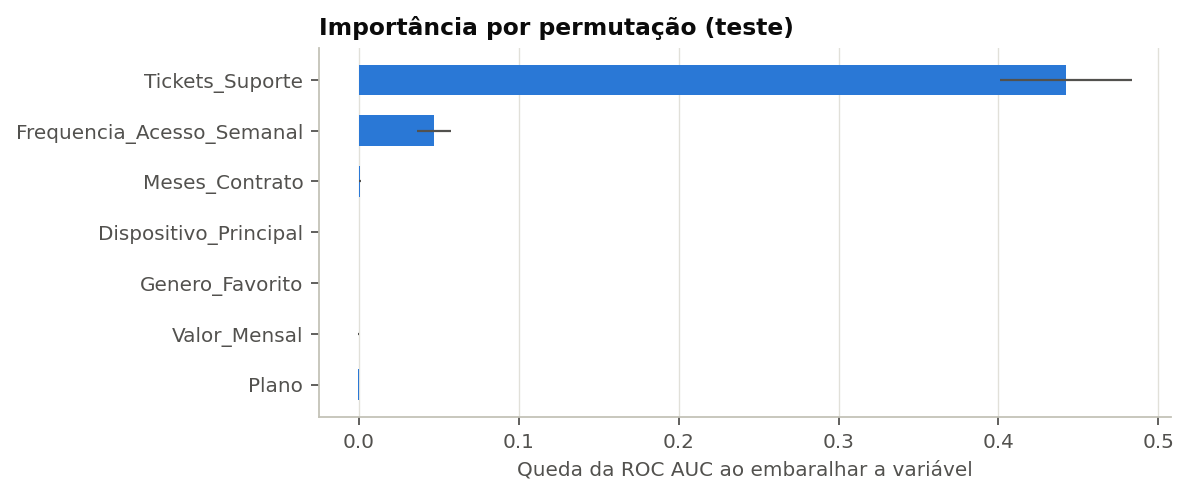

In [29]:
# Importância por permutação no teste: quanto a AUC cai ao embaralhar cada variável
imp = permutation_importance(modelo_final, X_te, y_te, scoring='roc_auc', n_repeats=30, random_state=SEED, n_jobs=1)
tab_imp = pd.DataFrame({'queda média da AUC': imp.importances_mean, 'dp': imp.importances_std},
                       index=X_te.columns).sort_values('queda média da AUC')
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(tab_imp.index, tab_imp['queda média da AUC'], xerr=tab_imp['dp'], color=AZUL, height=0.6, error_kw=dict(ecolor=TINTA2, lw=1))
ax.set(xlabel='Queda da ROC AUC ao embaralhar a variável', title='Importância por permutação (teste)')
ax.grid(axis='y', visible=False)
salvar(fig, 'fig16_importancia.png')
display(tab_imp.sort_values('queda média da AUC', ascending=False).round(4))
RES['importancia'] = tab_imp['queda média da AUC'].round(4).to_dict()

**Discussão do desempenho**
No limiar 0,50, o Gradient Boosting teve precisão de 93,6% e recall de 95,4% no teste (5 cancelamentos não identificados). No limiar 0,17, escolhido pelo custo no treino, o recall foi de 100% e a precisão de 83,7%: os contatos desnecessários subiram de 7 para 21 para que nenhum cancelamento fosse perdido. O custo ilustrativo no teste caiu de u.m. 811,90 para u.m. 482,32 (−40,6%); contatar todos custaria u.m. 2.083,46. O custo menor só tem significado sob as premissas declaradas, e recall de 100% em 200 clientes não garante o mesmo desempenho em outros clientes ou períodos.

No teste, Regressão Logística e SVM tiveram AUC ligeiramente maior (0,984) que o Gradient Boosting (0,982); como o modelo foi fixado antes, isso é diagnóstico e não motiva troca. Proximidade entre treino, CV e teste não prova ausência de sobreajuste; a curva de validação mostra a Random Forest chegando a AUC 1,0 no treino com árvores profundas, sem ganho na validação. A importância por permutação (queda de AUC de 0,44 para Tickets_Suporte e 0,05 para frequência; as demais ≈ 0) mede a dependência do modelo avaliado, não causalidade.

## 5. Análise crítica
### 5.1 Comparações exploratórias no treino
Ablamos atributos e testamos uma hipótese semântica sobre meses, usando CV no treino. Reutilizar hiperparâmetros escolhidos no mesmo treino faz dessas comparações diagnósticos condicionais, não uma nova avaliação aninhada independente. Seus resultados não alteram o modelo final.


In [30]:
modelo_base = clone(modelo_final.named_steps['modelo'])
def auc_cv(num, cat, X_=None, modelo=None):
    X_ = X_tr if X_ is None else X_
    s = cross_validate(pipeline(clone(modelo if modelo is not None else modelo_base), num, cat), X_, y_tr, cv=cv_ext, scoring='roc_auc')
    return s['test_score'].mean(), s['test_score'].std()

X_tr_36 = X_tr.assign(Meses_Contrato=X_tr['Meses_Contrato'].clip(upper=36))
cenarios = {
    'A. Modelo completo (7 variáveis)': auc_cv(NUM, CAT),
    'B. Sem Tickets_Suporte': auc_cv([c for c in NUM if c != 'Tickets_Suporte'], CAT),
    'C. Só Tickets + Acessos (Regressão Logística)': auc_cv(['Tickets_Suporte', 'Frequencia_Acesso_Semanal'], [], modelo=LogisticRegression(max_iter=2000)),
    'D. Meses_Contrato truncado em 36': auc_cv(NUM, CAT, X_=X_tr_36),
}
tab_cen = pd.DataFrame(cenarios, index=['AUC CV', 'dp']).T
display(tab_cen.round(3))
RES['cenarios'] = {k: float(v[0]) for k, v in cenarios.items()}

,AUC CV,dp
A. Modelo completo (7 variáveis),0.977,0.010
B. Sem Tickets_Suporte,0.681,0.036
C. Só Tickets + Acessos (Regressão Logística),0.981,0.009
D. Meses_Contrato truncado em 36,0.977,0.010


In [31]:
# Segmentação × modelo: com o mesmo número de contatos, quem acha mais cancelamentos no teste?
taxa_persona_tr = df.loc[X_tr.index].groupby('Persona')[ALVO].mean()
personas_alvo = taxa_persona_tr[taxa_persona_tr >= 0.6].index.tolist()
alvo_seg = df.loc[X_te.index, 'Persona'].isin(personas_alvo).to_numpy()
n_contatos = int(alvo_seg.sum())
alvo_mod = np.zeros(len(X_te), dtype=bool); alvo_mod[np.argsort(-p_final)[:n_contatos]] = True

linhas = []
codigos = ', '.join(p.split()[0] for p in personas_alvo)
for nome, sel in [(f'Personas de alto risco ({codigos})', alvo_seg),
                  (f'Modelo: {n_contatos} maiores probabilidades', alvo_mod)]:
    linhas.append({'abordagem': nome, 'contatos': int(sel.sum()), 'cancelamentos captados': int((sel & (y_te == 1)).sum()),
                   'recall': recall_score(y_te, sel), 'precisão': precision_score(y_te, sel,zero_division=0),
                   'custo ilustrativo (u.m.)': C_FP * valor_te[sel & (y_te == 0)].sum() + C_FN * valor_te[~sel & (y_te == 1)].sum()})
tab_seg_mod = pd.DataFrame(linhas).set_index('abordagem')
display(tab_seg_mod.round(3))
RES['seg_vs_modelo'] = tab_seg_mod.round(4).reset_index().to_dict(orient='records'); RES['personas_alvo'] = personas_alvo


,contatos,cancelamentos captados,recall,precisão,custo ilustrativo (u.m.)
abordagem,,,,,
"Personas de alto risco (G1, G2, G3)",105,92,0.852,0.876,2420.640
Modelo: 105 maiores probabilidades,105,98,0.907,0.933,1478.165


In [32]:
# Checagem de equidade: o modelo erra mais em algum grupo? (teste, limiar de custo)
prev_te = p_final >= T_OTIMO
linhas = []
for c in ['Dispositivo_Principal', 'Plano']:
    for g in sorted(X_te[c].unique()):
        m = (X_te[c] == g).to_numpy(); yt_g = y_te.to_numpy()[m]; pv = prev_te[m]
        linhas.append({'variável': c, 'grupo': g, 'n': int(m.sum()), 'taxa de churn': yt_g.mean(),
                       'FP': int((pv & (yt_g == 0)).sum()), 'recall': recall_score(yt_g, pv), 'taxa de falso positivo': (pv & (yt_g == 0)).sum() / max((yt_g == 0).sum(), 1),
                       'precisão': precision_score(yt_g, pv, zero_division=0)})
tab_eq = pd.DataFrame(linhas).set_index(['variável', 'grupo'])
display(tab_eq.round(3))
RES['equidade'] = tab_eq.round(4).reset_index().to_dict(orient='records')

n  taxa de churn  FP  recall  taxa de falso positivo  precisão
variável              grupo                                                                    
Dispositivo_Principal Mobile    63          0.587   7     1.0                   0.269     0.841
                      Smart TV  69          0.493   6     1.0                   0.171     0.850
                      Web       68          0.544   8     1.0                   0.258     0.822
Plano                 Basico    66          0.530   8     1.0                   0.258     0.814
                      Premium   70          0.543   5     1.0                   0.156     0.884
                      Standard  64          0.547   8     1.0                   0.276     0.814

### 5.2 Priorização exploratória por associação ao churn registrado
A lista combina escores OOF do treino e escores do teste reservado, identificando sua origem. Os primeiros vêm de modelos treinados em subconjuntos; os segundos, do modelo treinado nos 800 clientes. Portanto, o ranking combinado é apenas demonstrativo, com escores não calibrados de procedimentos distintos.

Não é uma lista validada de clientes ativos nem previsão para o próximo mês: inclui registros cujo churn já é conhecido. As faixas são convenções ilustrativas e não probabilidades garantidas. Para uso real, seria preciso definir datas, horizonte e elegibilidade, validar temporalmente e aplicar um modelo único calibrado aos clientes ativos.


In [33]:
# Não refaz treino com o teste nem trata esta lista como previsão futura.
escores=pd.Series(index=df.index,dtype=float)
escores.loc[X_tr.index]=p_oof;escores.loc[X_te.index]=p_final
faixa=np.where(escores>=0.70,'Alta',np.where(escores>=T_OTIMO,'Média','Baixa'))
lista=pd.DataFrame({'ID_Cliente':df.ID_Cliente,'Persona':df.Persona,'Escore_Churn':escores,'Origem_Escore':np.where(df.index.isin(X_tr.index),'OOF treino com busca interna','Teste reservado'),'Faixa_Exploratoria':faixa,'Churn_Registrado':y,'Valor_Mensal':df.Valor_Mensal,'Acao_Hipotetica':[ACOES[p] if f!='Baixa' else 'Monitoramento exploratório' for p,f in zip(df.Persona,faixa)]}).sort_values('Escore_Churn',ascending=False)
lista.to_csv(PASTA/'lista_priorizacao_churn.csv',index=False,encoding='utf-8-sig');display(lista.head(10))
print('Lista exploratória de registros rotulados; não é previsão do próximo mês nem lista de clientes ativos.')
RES['priorizacao']={'natureza':'demonstrativa; dados rotulados; escores não calibrados de treino OOF e teste','clientes':len(lista)}


Lista exploratória de registros rotulados; não é previsão do próximo mês nem lista de clientes ativos.


,ID_Cliente,Persona,Escore_Churn,Origem_Escore,Faixa_Exploratoria,Churn_Registrado,Valor_Mensal,Acao_Hipotetica
993,GS-0994,"G1 muitos tickets, uso baixo, contrato curto",0.991807,Teste reservado,Alta,1,46.39,Recuperação pelo suporte: contato proativo para resolver chamados e entender o motivo; oferta só após resolver
296,GS-0297,"G1 muitos tickets, uso baixo, contrato curto",0.991563,Teste reservado,Alta,1,56.09,Recuperação pelo suporte: contato proativo para resolver chamados e entender o motivo; oferta só após resolver
391,GS-0392,"G1 muitos tickets, uso baixo, contrato curto",0.991345,Teste reservado,Alta,1,35.49,Recuperação pelo suporte: contato proativo para resolver chamados e entender o motivo; oferta só após resolver
213,GS-0214,"G1 muitos tickets, uso baixo, contrato curto",0.991345,Teste reservado,Alta,1,34.10,Recuperação pelo suporte: contato proativo para resolver chamados e entender o motivo; oferta só após resolver
528,GS-0529,"G1 muitos tickets, uso baixo, contrato curto",0.991198,OOF treino com busca interna,Alta,1,49.45,Recuperação pelo suporte: contato proativo para resolver chamados e entender o motivo; oferta só após resolver
552,GS-0553,"G1 muitos tickets, uso baixo, contrato curto",0.991003,OOF treino com busca interna,Alta,1,31.83,Recuperação pelo suporte: contato proativo para resolver chamados e entender o motivo; oferta só após resolver
16,GS-0017,"G1 muitos tickets, uso baixo, contrato curto",0.990942,OOF treino com busca interna,Alta,1,31.89,Recuperação pelo suporte: contato proativo para resolver chamados e entender o motivo; oferta só após resolver
508,GS-0509,"G1 muitos tickets, uso baixo, contrato curto",0.990892,OOF treino com busca interna,Alta,1,50.71,Recuperação pelo suporte: contato proativo para resolver chamados e entender o motivo; oferta só após resolver
921,GS-0922,"G2 muitos tickets, uso baixo, contrato longo",0.990857,Teste reservado,Alta,1,45.97,Recuperação pelo suporte: contato proativo para resolver chamados e entender o motivo; oferta só após resolver
764,GS-0765,"G2 muitos tickets, uso baixo, contrato longo",0.990857,Teste reservado,Alta,1,46.91,Recuperação pelo suporte: contato proativo para resolver chamados e entender o motivo; oferta só após resolver


In [34]:
# Validações dirigidas às correções desta revisão.
checks={}
checks['particoes_sem_intersecao']=set(df.loc[X_tr.index,'ID_Cliente']).isdisjoint(df.loc[X_te.index,'ID_Cliente'])
checks['id_e_alvo_excluidos']=not set(['ID_Cliente','Churn','Persona','cluster']) & set(X.columns)
checks['segmentacao_aprendeu_800']=int(scaler_seg.named_steps['escala'].n_samples_seen_)==len(X_tr)
checks['pca_aprendeu_800']=pca.n_samples_==len(X_tr)
faltantes=X_tr[SEG].head(4).copy();faltantes.iloc[0,0]=np.nan;faltantes.iloc[1,1]=np.nan
checks['segmentacao_aceita_ausentes']=np.isfinite(scaler_seg.transform(faltantes)).all() and len(kmeans.predict(scaler_seg.transform(faltantes)))==4
checks['eda_aceita_inteiro_ausente']=faltantes.Frequencia_Acesso_Semanal.astype('Int64').isna().sum()==1
checks['classificador_aceita_ausentes_e_categoria_nova']=np.isfinite(modelo_final.predict_proba(cliente_incompleto)).all()
checks['metricas_conhecidas']=metricas(np.array([0,0,1,1]),np.array([.1,.8,.4,.9]))['FP']==1
checks['matriz_soma_teste']=sum(RES['teste_otimo'][k] for k in ['VP','FP','FN','VN'])==len(X_te)
checks['limiar_minimiza_grade']=np.isclose(custo(y_tr,p_oof,valor_tr,T_OTIMO),custos_tr.min())
checks['perfis_usam_treino']=int(perfil.clientes.sum())==len(X_tr)
checks['lista_identifica_origem']=lista.Origem_Escore.notna().all() and len(lista)==len(df)
checks['personas_com_nomes_unicos']=df_eda.Persona.nunique()==K
checks['categorias_com_grafia_original']=all(set(df[c].dropna())<=set(df_bruto[c].dropna().astype(str).str.strip()) for c in CAT)
checks['custo_exemplo_conhecido']=np.isclose(custo([0,1],[0.8,0.1],[20,30],0.5),100.0)
try:
    custo([0,1],[0.8,0.1],[np.nan,30],0.5)
    checks['custo_rejeita_mensalidade_ausente']=False
except ValueError:
    checks['custo_rejeita_mensalidade_ausente']=True
checks={k:bool(v) for k,v in checks.items()}
if not all(checks.values()):raise AssertionError(checks)
RES['testes']=checks
RES['versoes']={m:importlib.metadata.version(m) for m in ['pandas','scikit-learn','numpy','matplotlib','scipy','openpyxl']}
RES['ambiente']={'python':platform.python_version(),'sistema':platform.system()}
RES['criterio_modelo']='Maior ROC AUC na CV aninhada entre k-NN, SVM, Random Forest e Gradient Boosting'
RES['criterio_limiar']='Menor custo em OOF do treino com busca interna de hiperparâmetros por dobra; família pré-selecionada no treino'
def conv(o):
    if isinstance(o,np.integer):return int(o)
    if isinstance(o,np.floating):return float(o)
    if isinstance(o,np.ndarray):return o.tolist()
    return str(o)
(PASTA/'resultados.json').write_text(json.dumps(RES,ensure_ascii=False,indent=2,default=conv),encoding='utf-8')
(PASTA/'testes_validacao.json').write_text(json.dumps(checks,indent=2),encoding='utf-8')
print(f'{len(checks)} verificações aprovadas. Ambiente: {RES["ambiente"]}')
print(f'Resultados salvos na pasta {PASTA}/')


16 verificações aprovadas. Ambiente: {'python': '3.12.14', 'sistema': 'Linux'}
Resultados salvos na pasta resultados/


In [35]:
# Resumo dos números-chave desta execução (fonte para o relatório e o vídeo)
t05, tot = RES['teste_05'], RES['teste_otimo']
pol = {p['política']: p for p in RES['politicas']}
custo_05 = pol['Modelo, limiar 0,50']['custo ilustrativo (u.m.)']
custo_ot = pol[f'Modelo, limiar {num(T_OTIMO)}']['custo ilustrativo (u.m.)']
custo_todos = pol['Contatar todos (desconto genérico)']['custo ilustrativo (u.m.)']
top = tab_imp['queda média da AUC'].sort_values(ascending=False)
resumo = pd.DataFrame([
    ('Base', f"{len(df)} clientes, churn {pct(RES['taxa_churn_base'])}; treino {len(X_tr)} e teste {len(X_te)} (estratificado)"),
    ('Qualidade', f"{RES['auditoria']['ausentes']} ausentes, {RES['auditoria']['duplicatas']} duplicatas, {RES['outliers']['iqr']} outliers (IQR)"),
    ('Exploração', f"correlação com churn: tickets {num(RES['corr_alvo']['Tickets_Suporte'])}, acessos {num(RES['corr_alvo']['Frequencia_Acesso_Semanal'])}"),
    ('Segmentação', f"K-Means k={K}, silhouette {num(RES['silhouette_k'], 3)}, ARI {num(RES['ari_k'])}; churn por grupo de {pct(perfil.taxa_churn.min())} a {pct(perfil.taxa_churn.max())}"),
    ('PCA', f"PC1+PC2 preservam {pct(sum(RES['pca_var'][:2]))} da variância das 3 variáveis"),
    ('Modelo escolhido', f"{ESCOLHIDO} (AUC CV aninhada {num(tab_cv.loc[ESCOLHIDO, 'AUC CV'], 3)} ± {num(tab_cv.loc[ESCOLHIDO, 'AUC CV dp'], 3)})"),
    ('Teste, limiar 0,50', f"precisão {pct(t05['precisão'])}, recall {pct(t05['recall'])}, F1 {num(t05['F1'], 3)}, AUC {num(t05['ROC AUC'], 3)}"),
    (f'Teste, limiar {num(T_OTIMO)}', f"precisão {pct(tot['precisão'])}, recall {pct(tot['recall'])}, {int(tot['VP'] + tot['FP'])} contatos, FP {int(tot['FP'])}, FN {int(tot['FN'])}"),
    ('Custo ilustrativo (teste)', f"limiar {num(T_OTIMO)}: {brl(custo_ot)} · limiar 0,50: {brl(custo_05)} · contatar todos: {brl(custo_todos)}"),
    ('Variável mais importante', f"{top.index[0]} (queda de AUC {num(top.iloc[0], 3)}); sem ela a AUC CV cai para {num(RES['cenarios']['B. Sem Tickets_Suporte'], 3)}"),
], columns=['item', 'resultado']).set_index('item')
display(resumo)

,resultado
item,
Base,"1000 clientes, churn 54,2%; treino 800 e teste 200 (estratificado)"
Qualidade,"0 ausentes, 0 duplicatas, 0 outliers (IQR)"
Exploração,"correlação com churn: tickets 0,75, acessos -0,31"
Segmentação,"K-Means k=6, silhouette 0,293, ARI 0,72; churn por grupo de 5,3% a 100,0%"
PCA,"PC1+PC2 preservam 68,7% da variância das 3 variáveis"
Modelo escolhido,"Gradient Boosting (AUC CV aninhada 0,977 ± 0,010)"
"Teste, limiar 0,50","precisão 93,6%, recall 95,4%, F1 0,945, AUC 0,982"
"Teste, limiar 0,17","precisão 83,7%, recall 100,0%, 129 contatos, FP 21, FN 0"
Custo ilustrativo (teste),"limiar 0,17: u.m. 482,32 · limiar 0,50: u.m. 811,90 · contatar todos: u.m. 2.083,46"


**Leitura das comparações da seção 5.1**
- Sem Tickets_Suporte, a AUC da CV cai de 0,977 para 0,681: quase todo o poder preditivo depende dessa variável, o que torna sua temporalidade o principal risco de vazamento.
- Uma Regressão Logística só com tickets e acessos alcança AUC de 0,981: um modelo simples e explicável é suficiente nesta base.
- Truncar Meses_Contrato em 36 não muda o resultado (0,977).
- Com o mesmo número de contatos no teste (105), o modelo capta 98 cancelamentos contra 92 das personas de alto risco (G1–G3), com custo ilustrativo 39% menor. Nesta comparação do teste, o modelo identificou mais cancelamentos com o mesmo número de contatos; as personas ajudam a formular hipóteses sobre como abordar cada perfil.

**Limitações e melhorias**
1. A base estática não permite verificar se tickets antecedem churn. Chamados de cancelamento podem revelar o próprio alvo. Confirmar datas, motivos e janelas é prioritário.
2. Meses, unidade de frequência e moeda não estão documentados. Valores acima de 36 não são automaticamente erro; não se presume geração sintética.
3. A comparação de personas e classificador usa grupos aprendidos no treino. É uma avaliação descritiva única, sem otimização posterior no teste.
4. Erros por plano e dispositivo são diagnósticos com amostras pequenas (63 a 70 clientes por grupo). Diferenças de taxas exigem intervalos de incerteza; não se conclui equidade nem discriminação a partir dessas tabelas isoladas.
5. Silhouette e ARI não demonstram grupos naturais. Validar estabilidade em nova amostra e testar métodos para dados mistos são próximos passos.
6. Os custos são ilustrativos e os escores não calibrados. Avaliar calibração e Brier score, confirmar custos completos e realizar teste controlado antes de propor benefícios financeiros.
7. Prever um rótulo não demonstra que uma ação cause retenção. Campanhas precisam de grupo de controle; uplift é uma possibilidade futura com dados de tratamento apropriados.

**Ética e produção:** IDs não são atributos do modelo, mas podem ser vinculáveis a pessoas. Em uma base real, aplica-se a LGPD (Lei nº 13.709/2018): finalidade, necessidade, transparência e direito de revisão de decisões automatizadas (art. 20). Limitar coleta, acesso e retenção; proteger arquivos; permitir revisão humana. Não penalizar clientes que pedem suporte nem usar uma persona como rótulo permanente. Em produção, monitorar qualidade, mudanças de distribuição, calibração e desempenho por grupos relevantes.

## Conclusão
- **Dados:** 1.000 clientes, sem ausentes ou duplicatas; nenhum outlier detectado no treino pelos critérios adotados; churn de 54,2%. A base não tem datas, então o trabalho classifica o churn registrado, sem previsão temporal validada.
- **Segmentação:** o K-Means com 6 grupos (silhouette de 0,29) separa perfis com churn de 5% a 100%. Os três grupos com muitos tickets concentram 79,5% dos cancelamentos do treino.
- **Classificação:** entre Random Forest, Gradient Boosting, SVM e k-NN, o Gradient Boosting teve a maior AUC na validação cruzada aninhada (0,977). No teste: AUC de 0,982 (IC 95% bootstrap de 0,963 a 0,994).
- **Decisão:** com o limiar de 0,17, o modelo identificou os 108 cancelamentos do teste com 21 contatos desnecessários (precisão de 83,7%), reduzindo em 40,6% o custo ilustrativo frente ao limiar 0,50.
- **Ressalva central:** Tickets_Suporte responde por quase todo o desempenho; antes de qualquer uso real, é preciso confirmar que os tickets são registrados antes do cancelamento e testar as ações em piloto com grupo de controle.

Os números desta execução estão na célula de resumo acima e em `resultados/resultados.json`.

**Referências técnicas:** documentação scikit-learn 1.8 — [pipelines e vazamento](https://scikit-learn.org/1.8/common_pitfalls.html), [CV aninhada](https://scikit-learn.org/1.8/auto_examples/model_selection/plot_nested_cross_validation_iris.html), [clustering](https://scikit-learn.org/1.8/modules/clustering.html), [PCA](https://scikit-learn.org/1.8/modules/decomposition.html), [métricas](https://scikit-learn.org/1.8/modules/model_evaluation.html).